# Evaluate Known campaigns with HMW data


 RUNNING ANALYSIS: Combined Families (CD3A, SP34) [Within-Family Z-Scored] (n = 197 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING (Including Old vs. New Score) ---
                                        Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
SCORE 2: Agnostic Gated + Invariant [↑ Better]                 0.434764       -0.434764 1.728316e-10 ***
     Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                 0.339653        0.339653 1.045571e-06 ***
                      Higher ESM-2 Fitness (Z)                 0.304285       -0.304285 1.378848e-05 ***
          Lower VH-VL Dipole (-ΔCharge Asym Z)                 0.296494        0.296494 2.331448e-05 ***
      SCORE 1: Old Static Composite [↑ Better]                 0.259743       -0.259743 2.278693e-04 ***
             Further from pH 7.4 (Δ|pI-7.4| Z)                 0.255559       -0.255559 2.895327e-04 ***
             Higher Net Charge (ΔNet Charge Z)                 0.234681       -0.234681 9.020199e-04 

/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


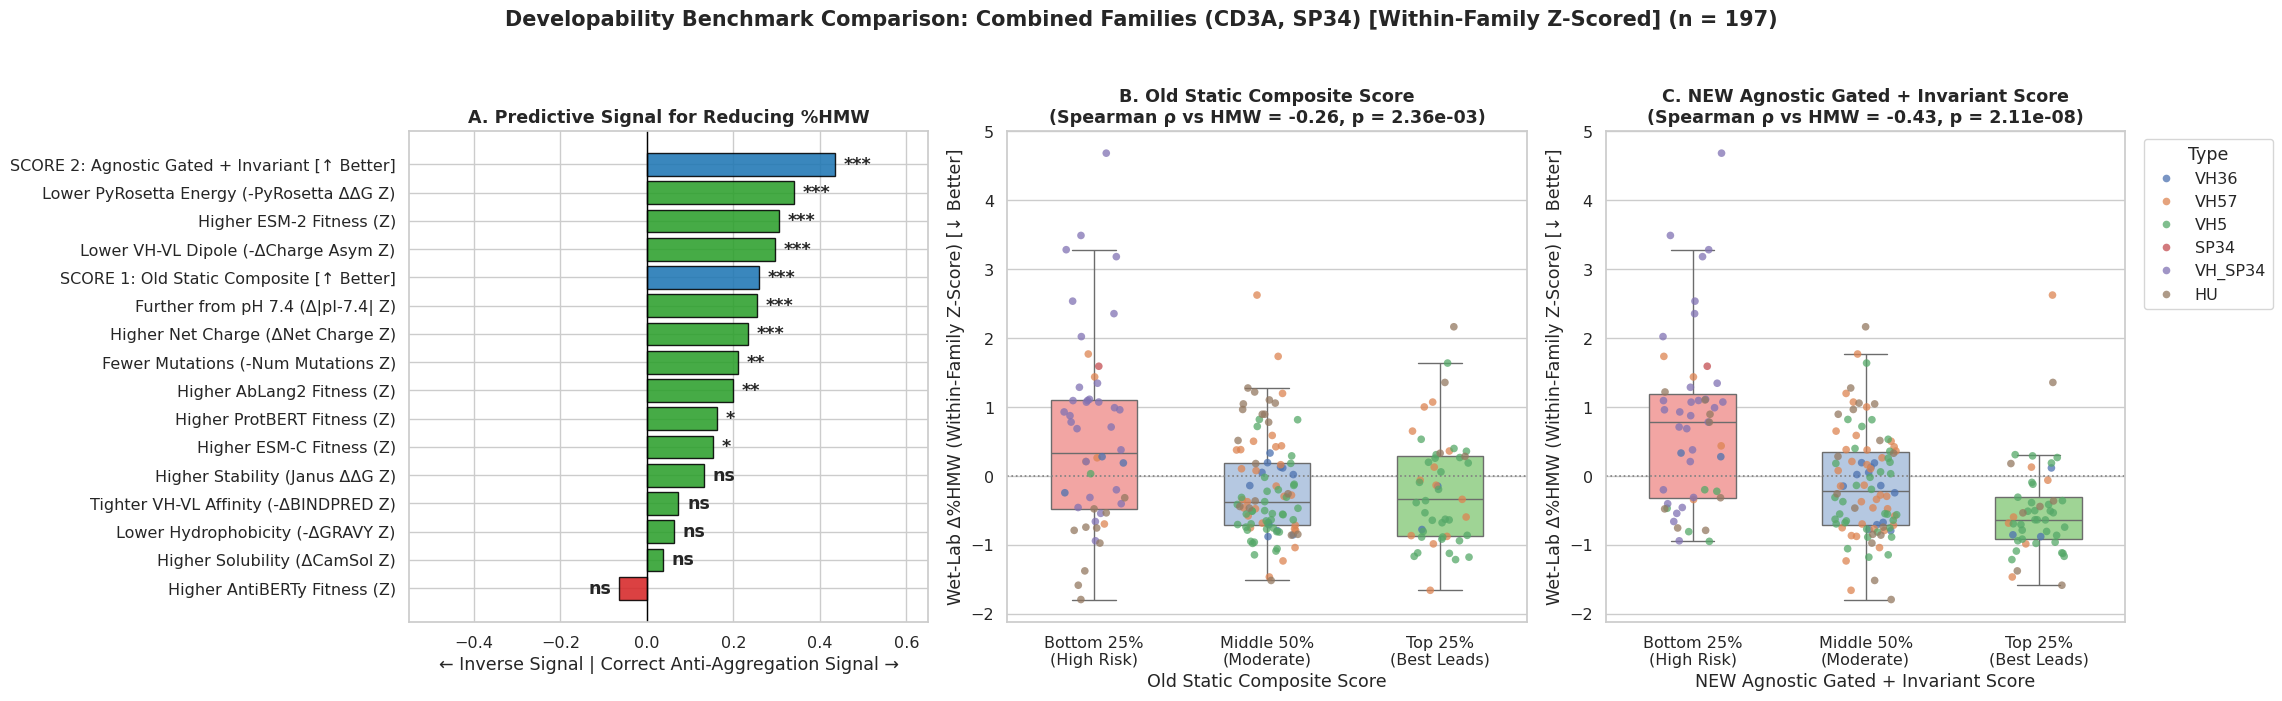

 -> Saved: hmw_benchmark_comparison_zscore_combined_CD3A_SP34.png


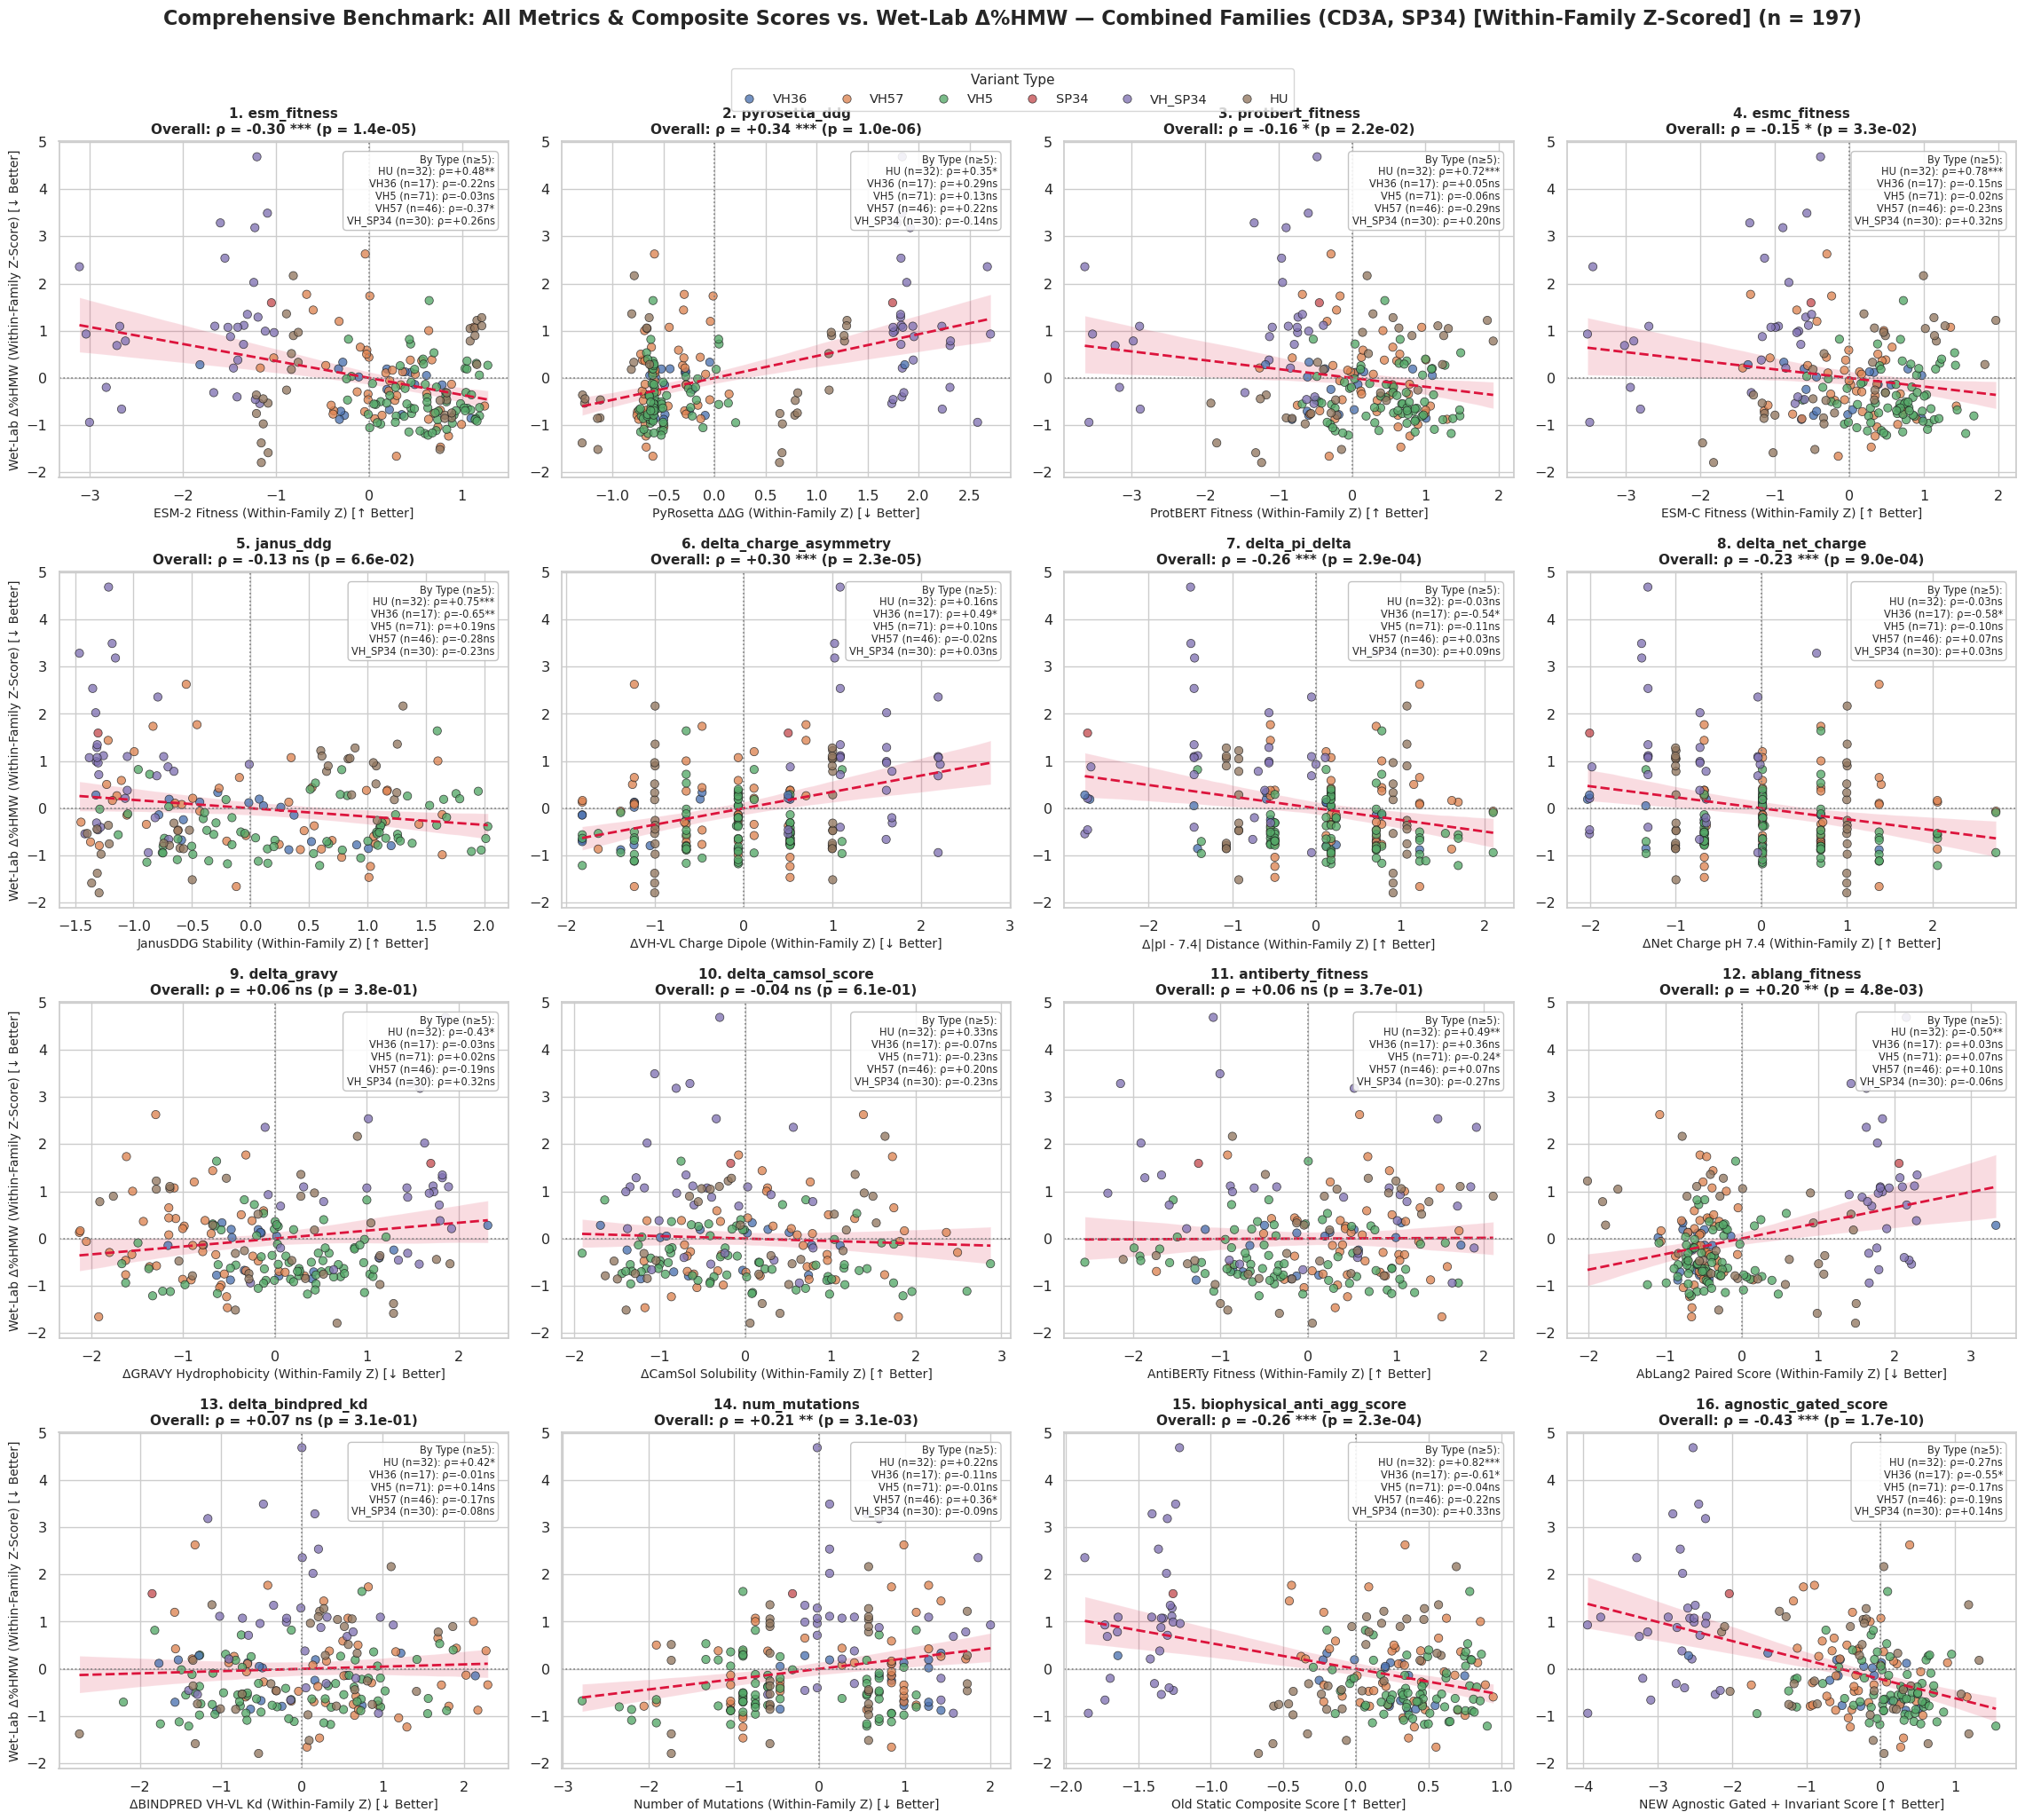

 -> Saved: all_metrics_scatter_grid_comparison_zscore_combined_CD3A_SP34.png


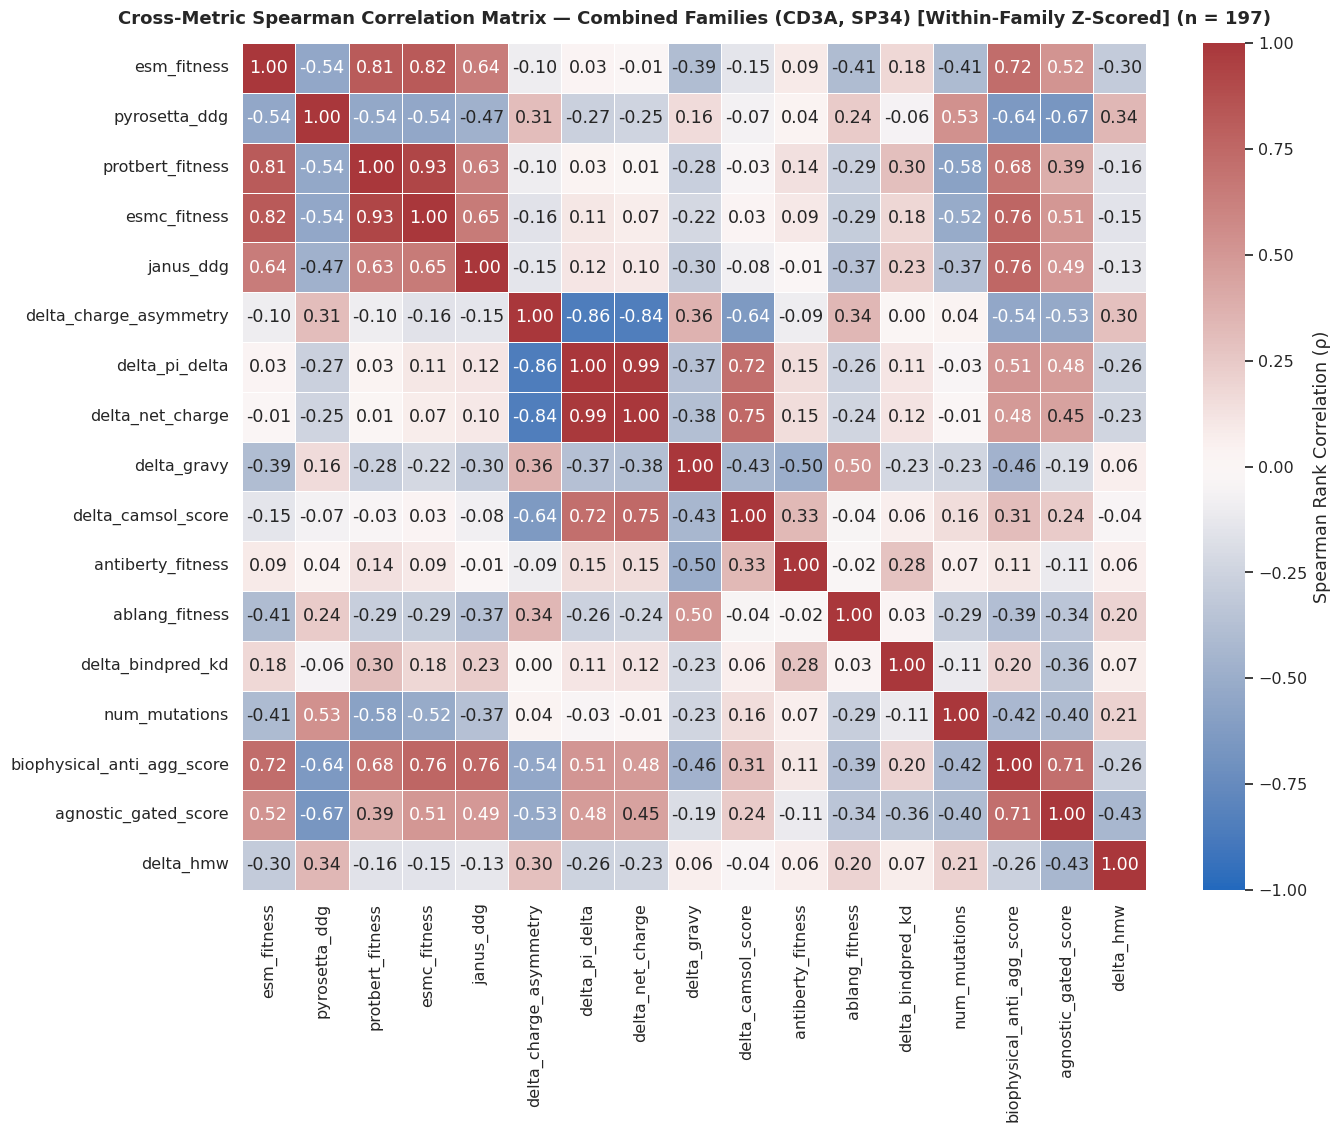

 -> Saved: metrics_cross_correlation_heatmap_comparison_zscore_combined_CD3A_SP34.png

 RUNNING ANALYSIS: Family: CD3A [Within-Family Z-Scored] (n = 165 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING (Including Old vs. New Score) ---
                                        Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
SCORE 2: Agnostic Gated + Invariant [↑ Better]                 0.470111       -0.470111 1.880423e-10 ***
                      Higher ESM-2 Fitness (Z)                 0.444850       -0.444850 2.147267e-09 ***
     Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                 0.413455        0.413455 3.398939e-08 ***
      SCORE 1: Old Static Composite [↑ Better]                 0.408295       -0.408295 5.212155e-08 ***
                   Higher ProtBERT Fitness (Z)                 0.384728       -0.384728 3.358846e-07 ***
                      Higher ESM-C Fitness (Z)                 0.384221       -0.384221 3.490517e-07 ***
                Higher Stability 

/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


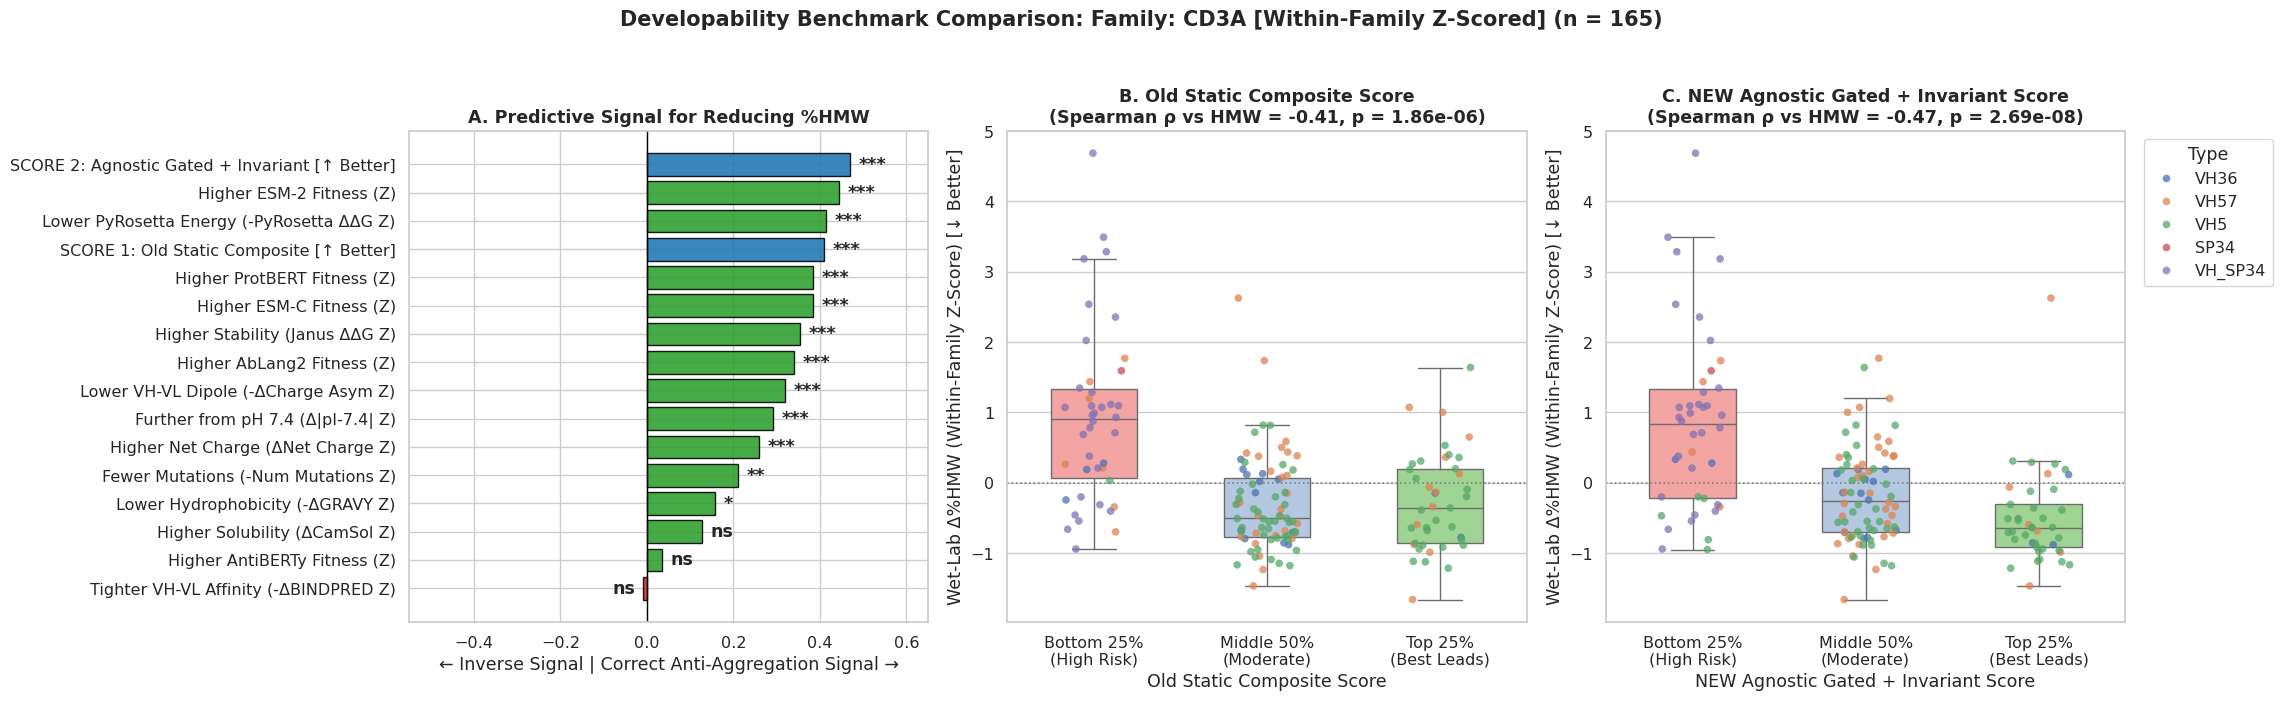

 -> Saved: hmw_benchmark_comparison_zscore_CD3A.png


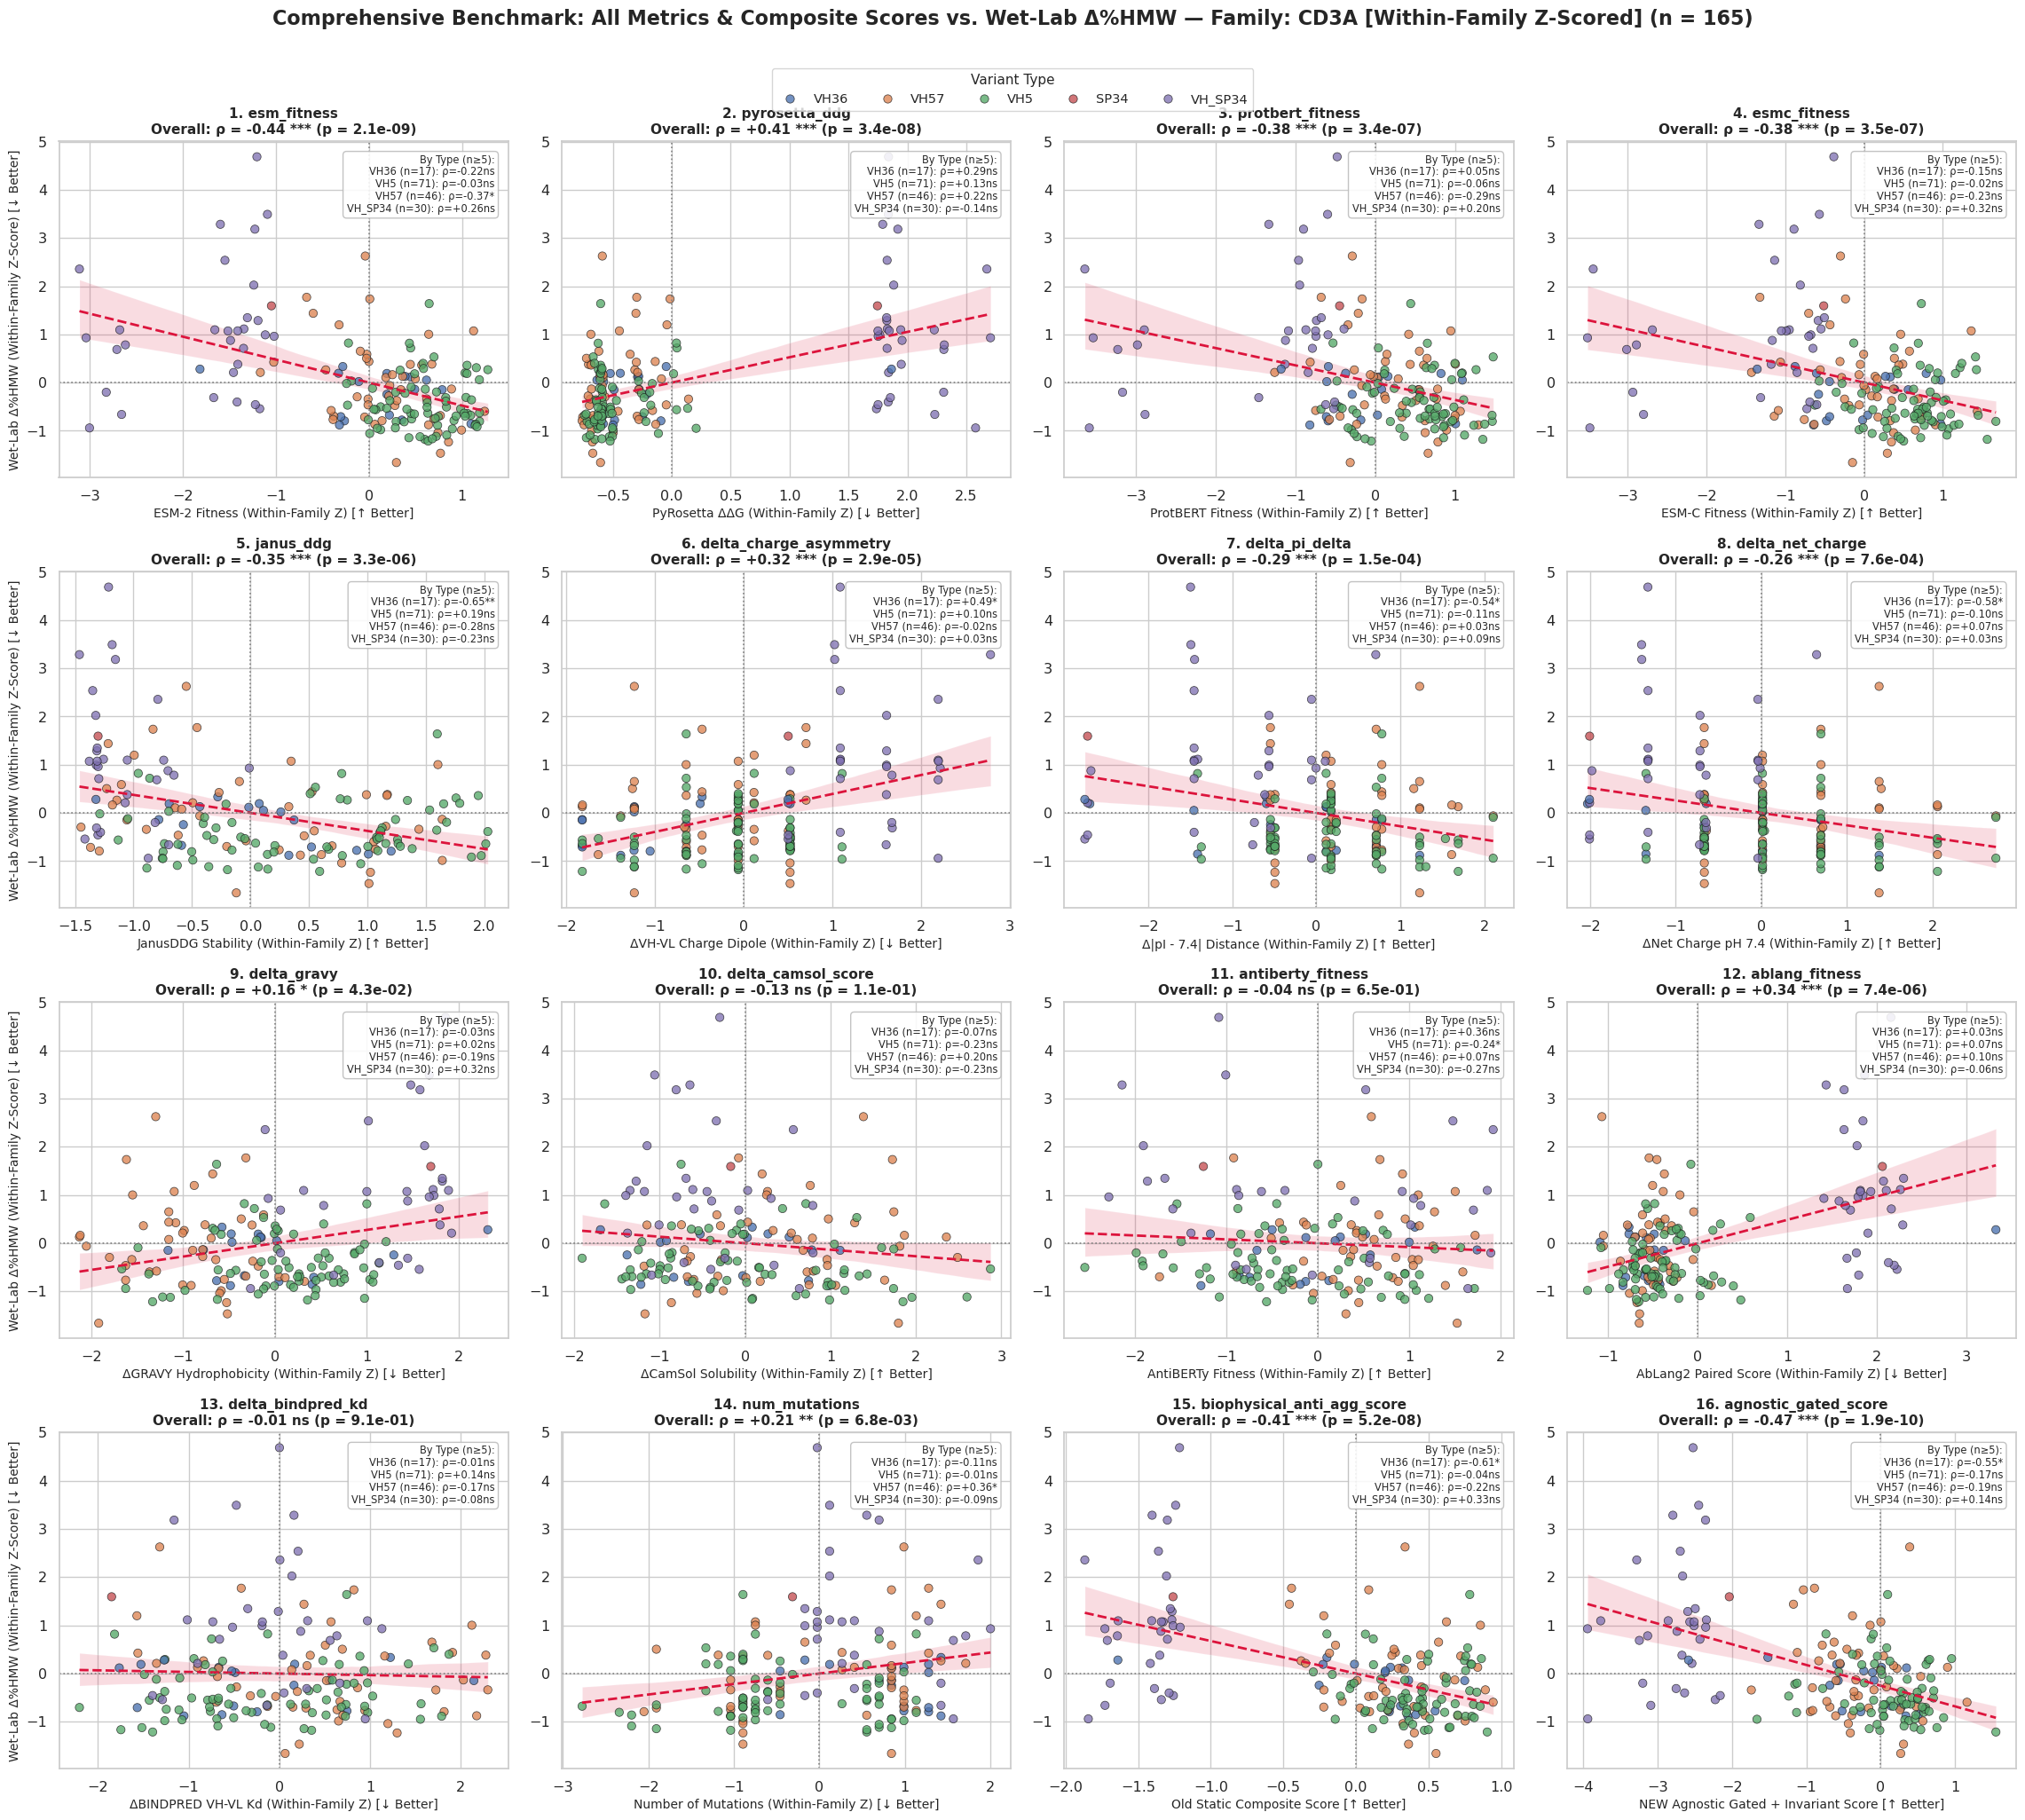

 -> Saved: all_metrics_scatter_grid_comparison_zscore_CD3A.png


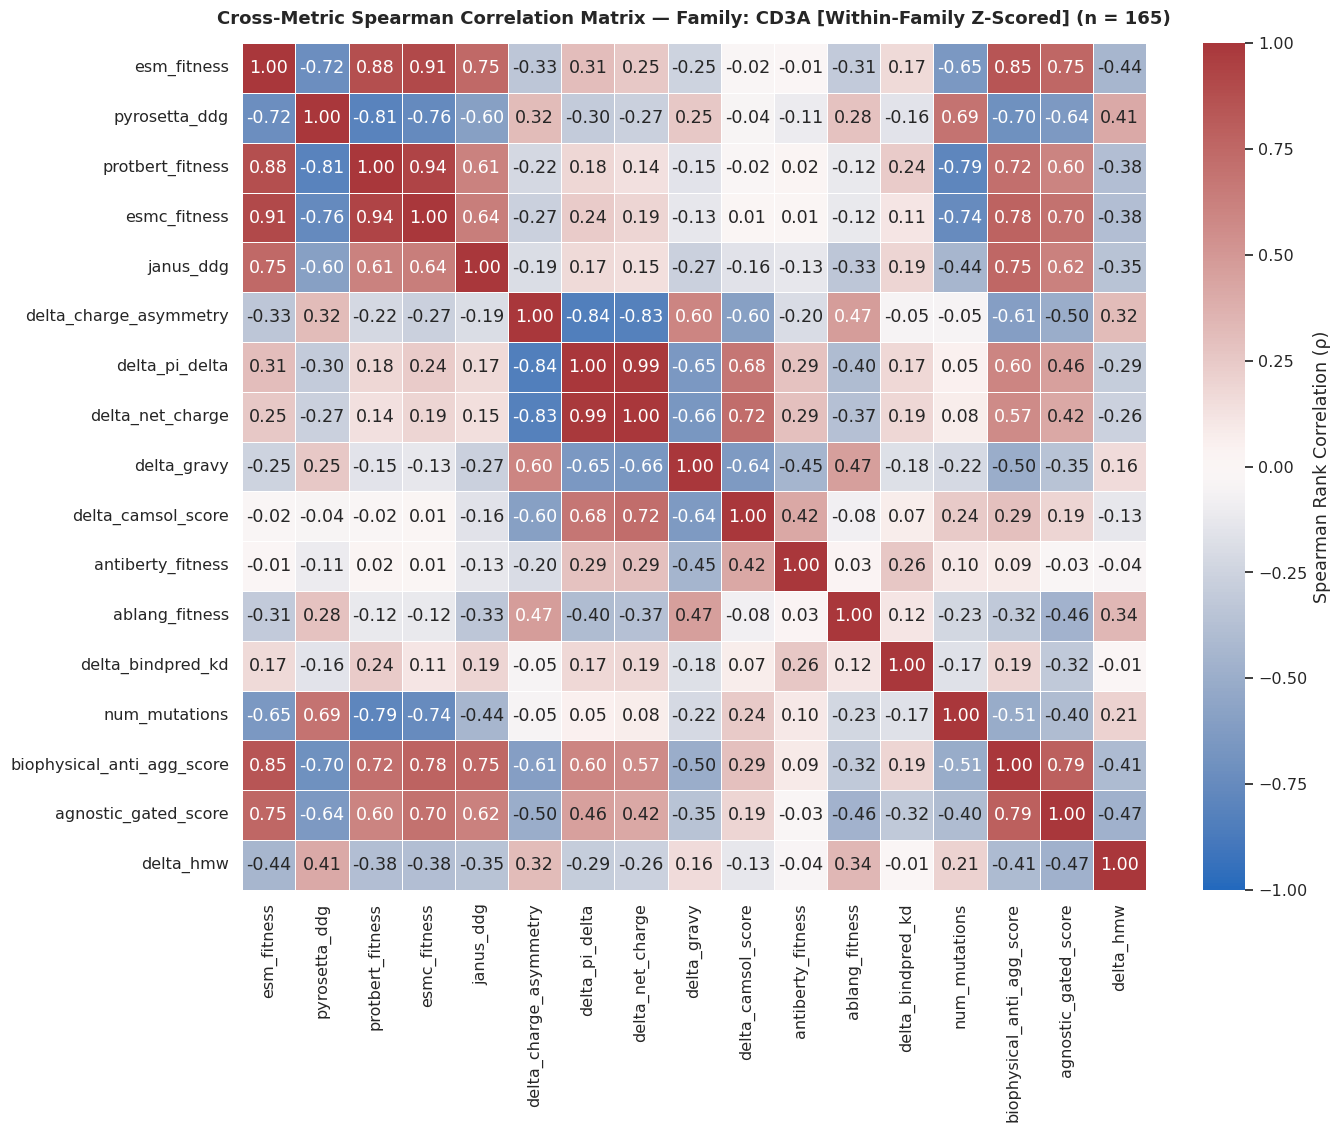

 -> Saved: metrics_cross_correlation_heatmap_comparison_zscore_CD3A.png

 RUNNING ANALYSIS: Family: SP34 [Within-Family Z-Scored] (n = 32 variants)

--- 1. BIOPHYSICAL SIGNAL RANKING (Including Old vs. New Score) ---
                                        Metric  Anti_Aggregation_Signal  Raw_Rho_vs_HMW      p_value Sig
         Tighter VH-VL Affinity (-ΔBINDPRED Z)                 0.416460        0.416460 1.774112e-02   *
     Lower PyRosetta Energy (-PyRosetta ΔΔG Z)                 0.351022        0.351022 4.885349e-02   *
SCORE 2: Agnostic Gated + Invariant [↑ Better]                 0.272202       -0.272202 1.317670e-01  ns
            Fewer Mutations (-Num Mutations Z)                 0.221315        0.221315 2.234896e-01  ns
          Lower VH-VL Dipole (-ΔCharge Asym Z)                 0.161973        0.161973 3.757955e-01  ns
             Further from pH 7.4 (Δ|pI-7.4| Z)                 0.025734       -0.025734 8.888145e-01  ns
             Higher Net Charge (ΔNet Charge Z)  

/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2637359/1088082669.py:326: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


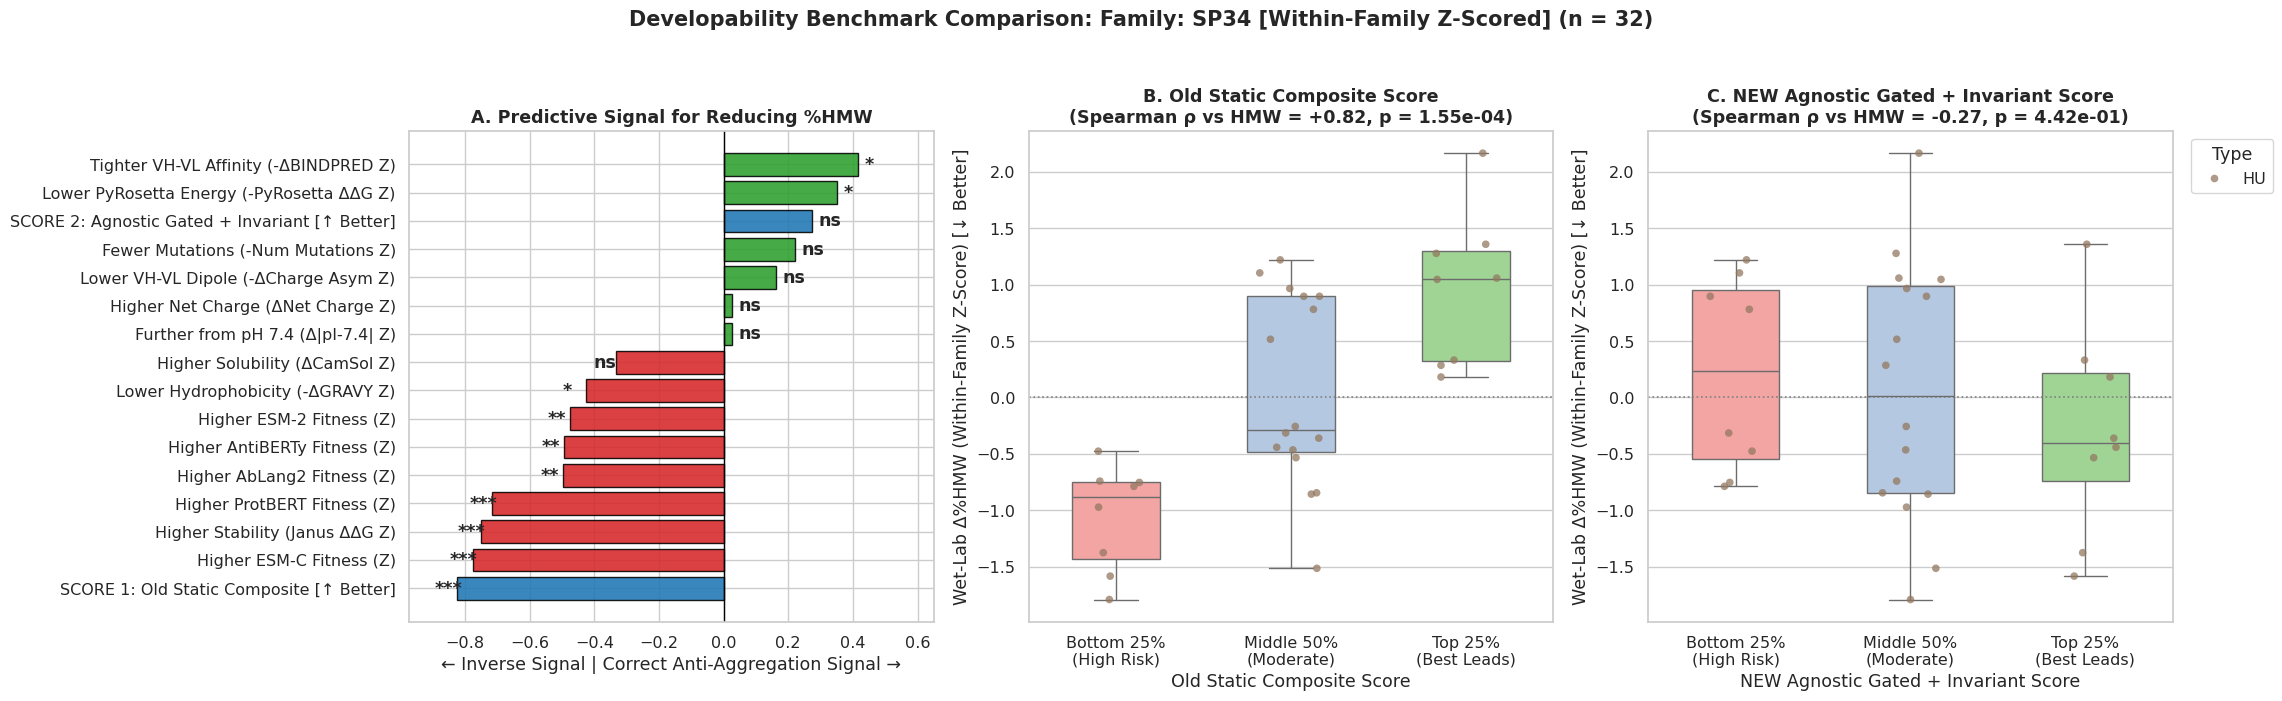

 -> Saved: hmw_benchmark_comparison_zscore_SP34.png


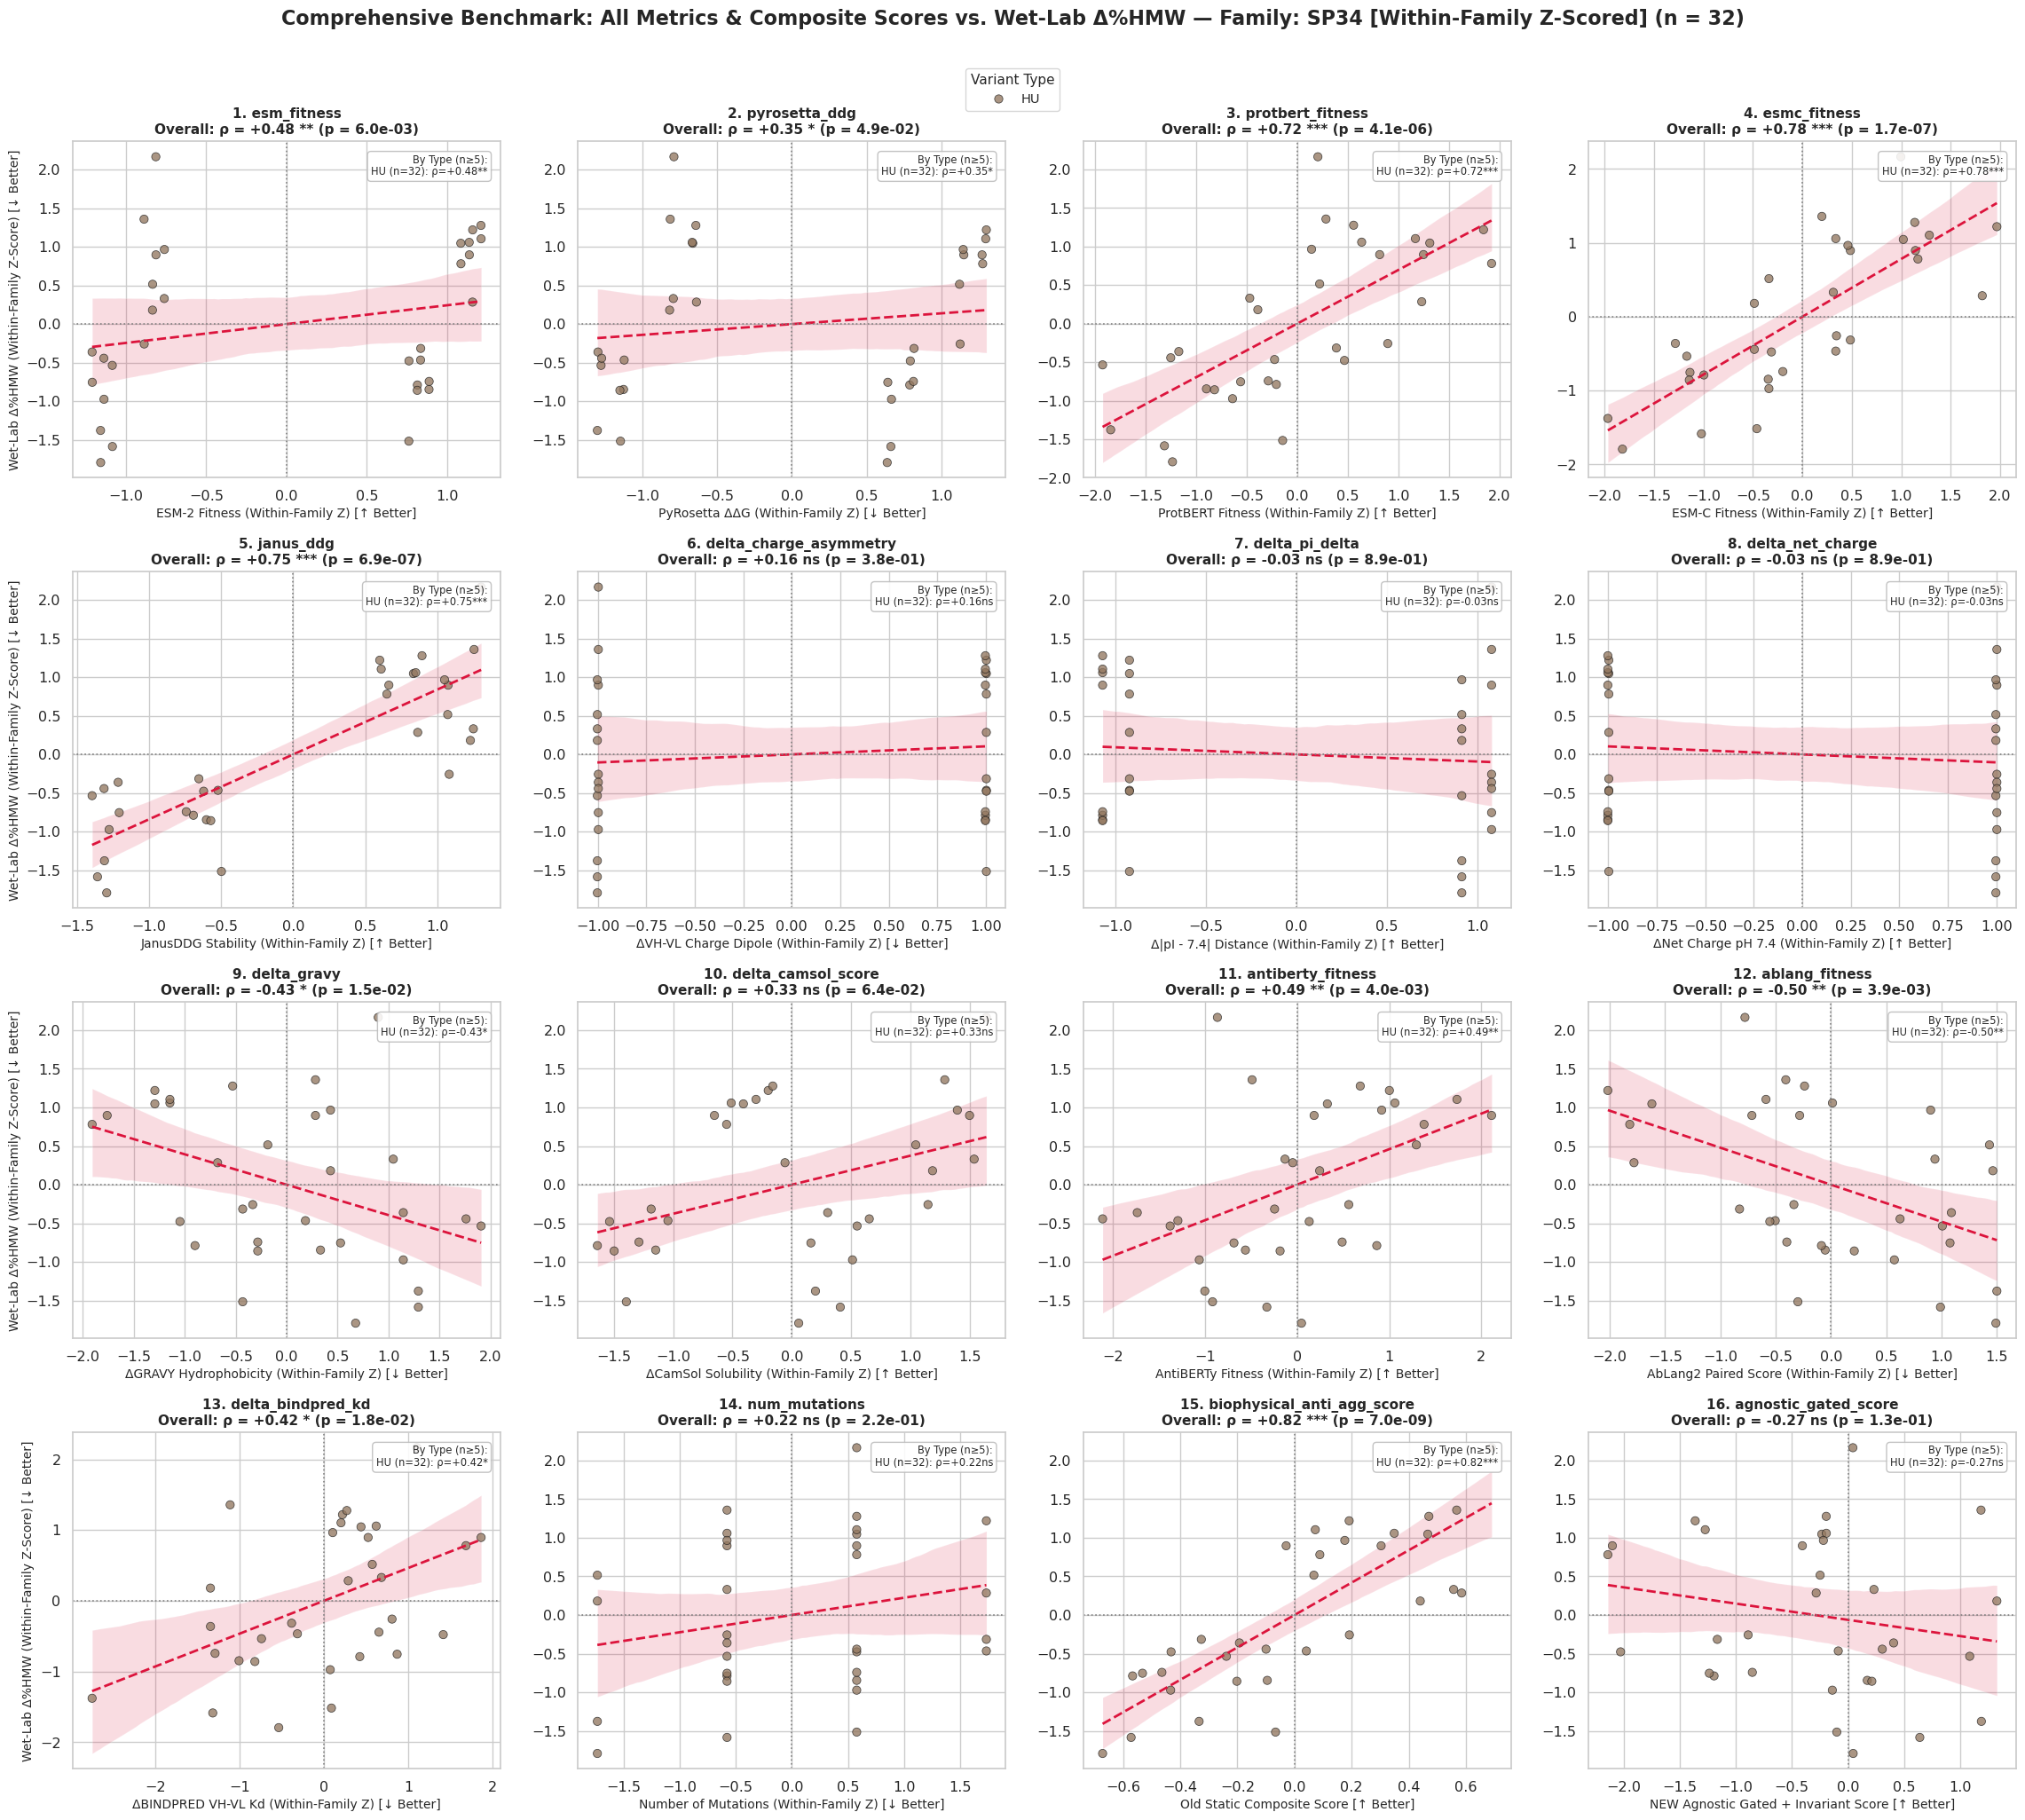

 -> Saved: all_metrics_scatter_grid_comparison_zscore_SP34.png


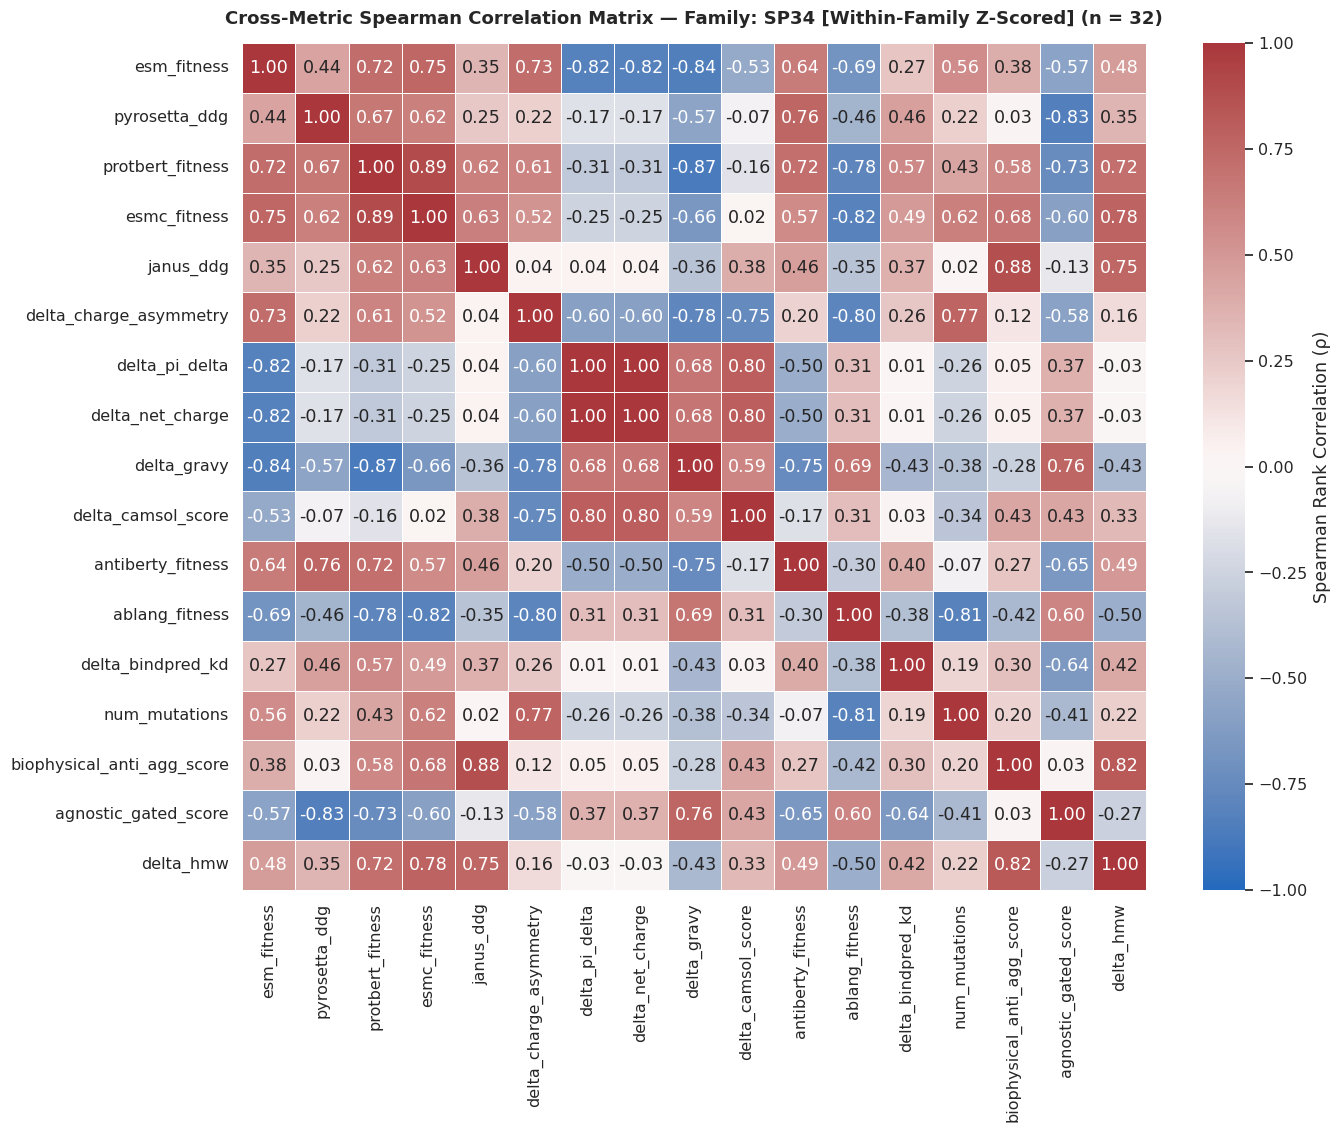

 -> Saved: metrics_cross_correlation_heatmap_comparison_zscore_SP34.png


In [55]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.preprocessing import StandardScaler

# Set clean plotting style
sns.set_theme(style="whitegrid", font_scale=1.05)

# Configuration Toggles
ZSCORE_TARGET_HMW = True
MIN_TYPE_SAMPLES = 5            # Minimum sequences required to compute/show per-Type Spearman
HIDE_SMALL_TYPES_IN_PLOTS = False

# ==========================================
# 1. Load Data & Standardize Columns
# ==========================================
input_csv = "COMBINED_developability_metrics.csv"
df = pd.read_csv(input_csv)
df.columns = df.columns.str.strip()

reverse_rename_map = {
    'ID': 'id', 'Sequence ID': 'id', 'Mutations': 'mutations',
    'Global Composite Score': 'global_composite_score',
    'Stability ΔΔG (Janus)': 'janus_ddg',
    'Stability ΔΔG (PyRosetta)': 'pyrosetta_ddg',
    'Intrinsic Solubility (CamSol)': 'camsol_score',
    'Isoelectric Point (pI)': 'pI',
    'Hydrophobicity Index (GRAVY)': 'gravy',
    'Net Charge (pH 7.4)': 'net_charge',
    'VH-VL Charge Delta': 'charge_asymmetry',
    'Affinity Log10 Kd (BINDPRED)': 'bindpred_kd',
    'ΔLog-Likelihood (ESM-2 General)': 'esm_fitness',
    'ΔLog-Likelihood (ESM-C)': 'esmc_fitness',
    'ΔLog-Likelihood (AntiBERTy)': 'antiberty_fitness',
    'ΔLog-Likelihood (AbLang2 Paired)': 'ablang_fitness',
    'ΔLog-Likelihood (ProtBERT)': 'protbert_fitness',
    'VH Sequence': 'VH', 'VL Sequence': 'VL',
    'Type': 'Type'
}
df = df.rename(columns=reverse_rename_map)

if 'Type' not in df.columns:
    df['Type'] = 'Unknown'
df['Type'] = df['Type'].fillna('Unknown').astype(str).str.strip()

df['pi_delta'] = (df['pI'] - 7.4).abs()

def count_muts(m):
    m_str = str(m).strip()
    if m_str in ['WT', 'nan', '']:
        return 0
    return len(m_str.split(','))

df['num_mutations'] = df['mutations'].apply(count_muts)

# ==========================================
# 2. Compute Within-Family Deltas, Downside Hinges & Z-Scores
# ==========================================
intrinsic_cols = [
    'camsol_score', 'gravy', 'charge_asymmetry', 
    'bindpred_kd', 'pi_delta', 'net_charge'
]
already_relative_cols = [
    'janus_ddg', 'pyrosetta_ddg', 'esm_fitness', 'esmc_fitness', 
    'antiberty_fitness', 'ablang_fitness', 'protbert_fitness', 'num_mutations'
]
all_feature_cols = [f'delta_{c}' for c in intrinsic_cols] + already_relative_cols

normalized_family_dfs = []

for fam, group in df.groupby('family'):
    group = group.copy()
    wt_matches = group[group['mutations'].astype(str).str.strip() == 'WT']
    if wt_matches.empty:
        print(f" -> WARNING: No WT row found for family '{fam}'. Skipping family.")
        continue
    wt_row = wt_matches.iloc[0]
    
    # Raw deltas relative to family WT
    group['raw_delta_hmw'] = group['hmw'] - wt_row['hmw']
    group['delta_hmw'] = group['raw_delta_hmw']
    
    for col in intrinsic_cols:
        if col in group.columns:
            group[f'delta_{col}'] = group[col] - wt_row[col]
            
    # Step 2B: Isolate mutants BEFORE Z-scoring so the WT row doesn't skew family mean/std
    mut_group = group[group['mutations'].astype(str).str.strip() != 'WT'].dropna(subset=['delta_hmw']).copy()
    if len(mut_group) < 3:
        continue

    # Preserve raw physical deltas before Z-scoring for Stage 1 / Hinge checks
    for col in all_feature_cols:
        if col in mut_group.columns:
            mut_group[f'raw_{col}'] = mut_group[col]

    # One-Sided Downside Hinge on Raw 1D Stability & Fitness (Penalize < 0 vs WT; cap > 0 at 0.0)
    # Prevents over-humanization (+40 ΔLL) from masking 3D steric clashes while penalizing unfolding (< 0)
    mut_group['hinge_esm']   = np.minimum(0.0, mut_group['raw_esm_fitness'].fillna(0.0))
    mut_group['hinge_janus'] = np.minimum(0.0, mut_group['raw_janus_ddg'].fillna(0.0))
    mut_group['hinge_camsol'] = np.minimum(0.0, mut_group['raw_delta_camsol_score'].fillna(0.0))

    scaler = StandardScaler()
    cols_to_scale = [c for c in all_feature_cols if c in mut_group.columns] + [
        'hinge_esm', 'hinge_janus', 'hinge_camsol'
    ]
    if ZSCORE_TARGET_HMW:
        cols_to_scale.append('delta_hmw')

    for col in cols_to_scale:
        valid_idx = mut_group[col].dropna().index
        if len(valid_idx) > 1 and mut_group.loc[valid_idx, col].nunique() > 1:
            mut_group.loc[valid_idx, col] = scaler.fit_transform(
                mut_group.loc[valid_idx, [col]]
            ).flatten()
        else:
            # If all variants passed the hinge (> 0 vs WT, like in SP34), hinge Z-score is 0.0 (no penalty)
            mut_group.loc[valid_idx, col] = 0.0

    normalized_family_dfs.append(mut_group)

# Pool the within-family Z-scored dataframes
mutants = pd.concat(normalized_family_dfs, ignore_index=True)

# Preserve original CSV appearance order and use Seaborn's 'deep' palette
all_types = list(mutants['Type'].unique())
palette_colors = sns.color_palette("deep", max(len(all_types), 3))
GLOBAL_TYPE_PALETTE = dict(zip(all_types, palette_colors))

families_in_csv = sorted(mutants['family'].astype(str).unique())
combined_file_tag = "_".join([re.sub(r'\W+', '', f) for f in families_in_csv])
combined_title_label = f"Combined Families ({', '.join(families_in_csv)}) [Within-Family Z-Scored]"

# ==========================================
# 3. Metric Definitions (16 Panels for 4x4 Grid)
# ==========================================
expected_good_direction = {
    'delta_camsol_score':         (+1, 'Higher Solubility (ΔCamSol Z)'),
    'janus_ddg':                  (+1, 'Higher Stability (Janus ΔΔG Z)'),
    'delta_pi_delta':             (+1, 'Further from pH 7.4 (Δ|pI-7.4| Z)'),
    'delta_charge_asymmetry':     (-1, 'Lower VH-VL Dipole (-ΔCharge Asym Z)'),
    'delta_net_charge':           (+1, 'Higher Net Charge (ΔNet Charge Z)'),
    'delta_gravy':                (-1, 'Lower Hydrophobicity (-ΔGRAVY Z)'),
    'delta_bindpred_kd':          (-1, 'Tighter VH-VL Affinity (-ΔBINDPRED Z)'),
    'pyrosetta_ddg':              (-1, 'Lower PyRosetta Energy (-PyRosetta ΔΔG Z)'),
    'esm_fitness':                (+1, 'Higher ESM-2 Fitness (Z)'),
    'esmc_fitness':               (+1, 'Higher ESM-C Fitness (Z)'),
    'antiberty_fitness':          (+1, 'Higher AntiBERTy Fitness (Z)'),
    'ablang_fitness':             (-1, 'Higher AbLang2 Fitness (Z)'),
    'protbert_fitness':           (+1, 'Higher ProtBERT Fitness (Z)'),
    'num_mutations':              (-1, 'Fewer Mutations (-Num Mutations Z)'),
    'biophysical_anti_agg_score': (+1, 'SCORE 1: Old Static Composite [↑ Better]'),
    'agnostic_gated_score':       (+1, 'SCORE 2: Agnostic Gated + Invariant [↑ Better]')
}

all_scatter_metrics = [
    ('esm_fitness',                'ESM-2 Fitness (Within-Family Z) [↑ Better]'),
    ('pyrosetta_ddg',              'PyRosetta ΔΔG (Within-Family Z) [↓ Better]'),
    ('protbert_fitness',           'ProtBERT Fitness (Within-Family Z) [↑ Better]'),
    ('esmc_fitness',               'ESM-C Fitness (Within-Family Z) [↑ Better]'),
    ('janus_ddg',                  'JanusDDG Stability (Within-Family Z) [↑ Better]'),
    ('delta_charge_asymmetry',     'ΔVH-VL Charge Dipole (Within-Family Z) [↓ Better]'),
    ('delta_pi_delta',             'Δ|pI - 7.4| Distance (Within-Family Z) [↑ Better]'),
    ('delta_net_charge',           'ΔNet Charge pH 7.4 (Within-Family Z) [↑ Better]'),
    ('delta_gravy',                'ΔGRAVY Hydrophobicity (Within-Family Z) [↓ Better]'),
    ('delta_camsol_score',         'ΔCamSol Solubility (Within-Family Z) [↑ Better]'),
    ('antiberty_fitness',          'AntiBERTy Fitness (Within-Family Z) [↑ Better]'),
    ('ablang_fitness',             'AbLang2 Paired Score (Within-Family Z) [↓ Better]'),
    ('delta_bindpred_kd',          'ΔBINDPRED VH-VL Kd (Within-Family Z) [↓ Better]'),
    ('num_mutations',              'Number of Mutations (Within-Family Z) [↓ Better]'),
    ('biophysical_anti_agg_score', 'Old Static Composite Score [↑ Better]'),
    ('agnostic_gated_score',       'NEW Agnostic Gated + Invariant Score [↑ Better]')
]

hmw_axis_label = "Wet-Lab Δ%HMW (Within-Family Z-Score) [↓ Better]" if ZSCORE_TARGET_HMW else "Wet-Lab Δ%HMW (%) [↓ Better]"

def get_sig_stars(pval):
    if pval < 0.001: return "***"
    if pval < 0.01:  return "**"
    if pval < 0.05:  return "*"
    return "ns"

# ==========================================
# 4. Modular Analysis & Plotting Function
# ==========================================
def run_developability_analysis(sub_df, title_label, file_tag):
    sub_df = sub_df.copy()
    
    # Optionally drop small Type groups (< MIN_TYPE_SAMPLES) from the subset entirely
    if HIDE_SMALL_TYPES_IN_PLOTS:
        type_counts = sub_df['Type'].value_counts()
        keep_types = type_counts[type_counts >= MIN_TYPE_SAMPLES].index
        sub_df = sub_df[sub_df['Type'].isin(keep_types)].copy()

    n_samples = len(sub_df)
    print(f"\n{'='*85}")
    print(f" RUNNING ANALYSIS: {title_label} (n = {n_samples} variants)")
    print(f"{'='*85}")

    # ---------------------------------------------------------
    # SCORE 1: Old Static Composite Score (Ungated Linear Sum)
    # ---------------------------------------------------------
    old_pillar_specs = [
        ('pyrosetta',  'pyrosetta_ddg',          -1.0, 0.20),
        ('janus',      'janus_ddg',              +1.0, 0.20),
        ('esm2',       'esm_fitness',            +1.0, 0.15),
        ('esmc',       'esmc_fitness',           +1.0, 0.15),
        ('low_dipole', 'delta_charge_asymmetry', -1.0, 0.10),
        ('repulsion',  'delta_pi_delta',         +1.0, 0.10),
        ('gravy',      'delta_gravy',            -1.0, 0.05),
        ('camsol',     'delta_camsol_score',     +1.0, 0.05)
    ]
    sub_df['biophysical_anti_agg_score'] = 0.0
    for _, col_name, direction, weight in old_pillar_specs:
        if col_name in sub_df.columns:
            sub_df['biophysical_anti_agg_score'] += weight * direction * sub_df[col_name].fillna(0.0)

    # ---------------------------------------------------------
    # SCORE 2: Agnostic Gated + Invariant Score (Zero-Shot)
    # ---------------------------------------------------------
    # Component A: Directionally Invariant 3D & Electrostatic Core (Never inverted in CD3A or SP34)
    invariant_core = (
        -0.30 * sub_df['pyrosetta_ddg'].fillna(0.0) +
        -0.25 * sub_df['delta_bindpred_kd'].fillna(0.0) +
        -0.20 * sub_df['delta_charge_asymmetry'].fillna(0.0) +
        +0.15 * sub_df['delta_pi_delta'].fillna(0.0) +
        -0.10 * sub_df['num_mutations'].fillna(0.0)
    )

    # Component B: One-Sided 1D Folding Downside Hinge (Active ONLY when variant degrades WT < 0)
    downside_folding_hinge = (
        +0.25 * sub_df['hinge_esm'].fillna(0.0) +
        +0.15 * sub_df['hinge_janus'].fillna(0.0) +
        +0.10 * sub_df['hinge_camsol'].fillna(0.0)
    )

    # Component C: Non-Compensatory Hard Gate Penalty (Weakest-Link AND Gate)
    # Penalizes variants that fall in the worst ~25% tail (Z > +0.67) of 3D clash, interface Kd, or 1D unfolding
    clash_fail     = (sub_df['pyrosetta_ddg'] > 0.67).astype(float)
    interface_fail = (sub_df['delta_bindpred_kd'] > 0.67).astype(float)
    unfold_fail    = ((sub_df['raw_esm_fitness'] < -10.0) | (sub_df['raw_janus_ddg'] < -0.5)).astype(float)
    gate_penalty   = -0.50 * (clash_fail + interface_fail + unfold_fail)

    sub_df['agnostic_gated_score'] = invariant_core + downside_folding_hinge + gate_penalty

    # Assign Quartile Tiers for BOTH Scores
    tier_labels = ['Bottom 25%\n(High Risk)', 'Middle 50%\n(Moderate)', 'Top 25%\n(Best Leads)']
    sub_df['Tier_Old'] = pd.qcut(
        sub_df['biophysical_anti_agg_score'].rank(method='first'),
        q=[0, 0.25, 0.75, 1.0], labels=tier_labels
    )
    sub_df['Tier_Agnostic'] = pd.qcut(
        sub_df['agnostic_gated_score'].rank(method='first'),
        q=[0, 0.25, 0.75, 1.0], labels=tier_labels
    )

    # --- A. Spearman Correlation Table ---
    corr_rows = []
    for col, (sign_dir, label) in expected_good_direction.items():
        if col not in sub_df.columns:
            continue
        valid = sub_df[['delta_hmw', col]].dropna()
        if len(valid) > 3 and valid[col].nunique() > 1:
            raw_rho, pval = spearmanr(valid[col], valid['delta_hmw'])
            anti_agg_rho = -1.0 * sign_dir * raw_rho
            corr_rows.append({
                'Metric': label,
                'Raw_col': col,
                'Raw_Rho_vs_HMW': raw_rho,
                'Anti_Aggregation_Signal': anti_agg_rho,
                'p_value': pval,
                'Sig': get_sig_stars(pval)
            })

    corr_df = pd.DataFrame(corr_rows).sort_values(by='Anti_Aggregation_Signal', ascending=False)
    print("\n--- 1. BIOPHYSICAL SIGNAL RANKING (Including Old vs. New Score) ---")
    if not corr_df.empty:
        print(corr_df[['Metric', 'Anti_Aggregation_Signal', 'Raw_Rho_vs_HMW', 'p_value', 'Sig']].to_string(index=False))

    print("\n--- 2A. OLD COMPOSITE SCORE TIERS ---")
    print(sub_df.groupby('Tier_Old', observed=False).agg(
        count=('delta_hmw', 'count'),
        z_hmw_median=('delta_hmw', 'median'),
        raw_hmw_median=('raw_delta_hmw', 'median'),
        raw_hmw_mean=('raw_delta_hmw', 'mean')
    ))

    print("\n--- 2B. NEW AGNOSTIC GATED SCORE TIERS ---")
    print(sub_df.groupby('Tier_Agnostic', observed=False).agg(
        count=('delta_hmw', 'count'),
        z_hmw_median=('delta_hmw', 'median'),
        raw_hmw_median=('raw_delta_hmw', 'median'),
        raw_hmw_mean=('raw_delta_hmw', 'mean')
    ))

    # =========================================================
    # FIGURE 1: 3-Panel Diagnostic Figure (Signal + Old Tiers vs. New Tiers)
    # =========================================================
    fig, axes = plt.subplots(1, 3, figsize=(23, 6.8))
    plt.subplots_adjust(wspace=0.32)

    # Panel A: Horizontal Bar Chart of Anti-Aggregation Signal
    ax1 = axes[0]
    plot_corr = corr_df.sort_values('Anti_Aggregation_Signal', ascending=True)
    if not plot_corr.empty:
        colors = [
            '#1f77b4' if 'SCORE' in m else ('#2ca02c' if val > 0 else '#d62728')
            for m, val in zip(plot_corr['Metric'], plot_corr['Anti_Aggregation_Signal'])
        ]
        bars = ax1.barh(plot_corr['Metric'], plot_corr['Anti_Aggregation_Signal'], color=colors, alpha=0.88, edgecolor='black')
        ax1.axvline(0, color='black', linewidth=1)
        ax1.set_title("A. Predictive Signal for Reducing %HMW", fontweight='bold')
        ax1.set_xlabel("← Inverse Signal | Correct Anti-Aggregation Signal →")
        
        for bar, sig in zip(bars, plot_corr['Sig']):
            width = bar.get_width()
            offset = 0.02 if width >= 0 else -0.07
            ax1.text(width + offset, bar.get_y() + bar.get_height()/2, sig, va='center', fontweight='bold')
        
        min_x = min(-0.55, plot_corr['Anti_Aggregation_Signal'].min() - 0.15)
        max_x = max(0.65, plot_corr['Anti_Aggregation_Signal'].max() + 0.15)
        ax1.set_xlim(min_x, max_x)

    # Helper to plot Panel B (Old Score) and Panel C (New Agnostic Score)
    def plot_tier_panel(ax, tier_col, score_col, panel_letter, panel_name, show_legend=False):
        sns.boxplot(
            data=sub_df, x=tier_col, y='delta_hmw', ax=ax,
            palette=['#ff9896', '#aec7e8', '#98df8a'], showfliers=False, width=0.5
        )
        sns.stripplot(
            data=sub_df, x=tier_col, y='delta_hmw', ax=ax,
            hue='Type', palette=GLOBAL_TYPE_PALETTE, dodge=False, alpha=0.75, jitter=0.18, size=5.5,
            legend=show_legend
        )
        ax.axhline(0, color='gray', linestyle=':', linewidth=1.2)
        
        top_hmw = sub_df[sub_df[tier_col] == 'Top 25%\n(Best Leads)']['delta_hmw']
        bot_hmw = sub_df[sub_df[tier_col] == 'Bottom 25%\n(High Risk)']['delta_hmw']
        # One-sided test: Does Top 25% have LOWER HMW than Bottom 25%? (Plus two-sided for reference)
        mw_p_two = mannwhitneyu(top_hmw, bot_hmw, alternative='two-sided')[1] if (len(top_hmw) > 0 and len(bot_hmw) > 0) else np.nan
        rho_s, _ = spearmanr(sub_df[score_col], sub_df['delta_hmw'])

        ax.set_title(f"{panel_letter}. {panel_name}\n(Spearman ρ vs HMW = {rho_s:+.2f}, p = {mw_p_two:.2e})", fontweight='bold')
        ax.set_xlabel(panel_name)
        ax.set_ylabel(hmw_axis_label)
        if show_legend:
            ax.legend(title='Type', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

    # Panel B: Old Static Composite Score
    plot_tier_panel(axes[1], 'Tier_Old', 'biophysical_anti_agg_score', 'B', 'Old Static Composite Score', show_legend=False)

    # Panel C: New Agnostic Gated Score
    plot_tier_panel(axes[2], 'Tier_Agnostic', 'agnostic_gated_score', 'C', 'NEW Agnostic Gated + Invariant Score', show_legend=True)

    fig.suptitle(f"Developability Benchmark Comparison: {title_label} (n = {n_samples})", fontsize=15, fontweight='bold', y=1.03)
    plt.tight_layout()
    diag_filename = f"hmw_benchmark_comparison_zscore_{file_tag}.png"
    plt.savefig(diag_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {diag_filename}")

    # =========================================================
    # FIGURE 2: 4x4 Grid of All 16 Metrics (Including Old & New Scores)
    # =========================================================
    fig, axes = plt.subplots(4, 4, figsize=(23, 20))
    plt.subplots_adjust(hspace=0.42, wspace=0.28)
    axes_flat = axes.flatten()

    legend_handles, legend_labels = None, None

    for idx, (col, label) in enumerate(all_scatter_metrics):
        ax = axes_flat[idx]
        if col not in sub_df.columns:
            ax.set_visible(False)
            continue
            
        valid = sub_df[[col, 'delta_hmw', 'Type']].dropna()
        
        if len(valid) <= 3 or valid[col].nunique() <= 1:
            ax.text(0.5, 0.5, f"{col}\n(Constant / No Variance)", ha='center', va='center', fontsize=12)
            ax.set_title(f"{idx+1}. {col} (Constant)", fontweight='bold', fontsize=11)
            continue

        # 1. Overall Spearman Correlation
        rho, pval = spearmanr(valid[col], valid['delta_hmw'])
        stars = get_sig_stars(pval)
        
        # 2. Overall OLS Regression Trendline (Red Dashed Line)
        sns.regplot(
            data=valid, x=col, y='delta_hmw', ax=ax,
            scatter=False,
            line_kws={'color': 'crimson', 'linestyle': '--', 'linewidth': 2}
        )
        
        # 3. Color-coded Scatter Points by 'Type'
        sns.scatterplot(
            data=valid, x=col, y='delta_hmw', hue='Type', palette=GLOBAL_TYPE_PALETTE,
            ax=ax, alpha=0.78, edgecolor='k', s=45, legend=(idx == 0)
        )
        
        # Capture legend handles from the first subplot, then remove in-plot legend box
        if idx == 0 and ax.get_legend() is not None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()

        # 4. Per-Type Spearman Calculation (Filtered to Types with n >= MIN_TYPE_SAMPLES)
        type_stat_lines = []
        for t_name, t_group in valid.groupby('Type'):
            if len(t_group) >= MIN_TYPE_SAMPLES and t_group[col].nunique() > 1 and t_group['delta_hmw'].nunique() > 1:
                t_rho, t_pval = spearmanr(t_group[col], t_group['delta_hmw'])
                t_stars = get_sig_stars(t_pval)
                type_stat_lines.append(f"{t_name} (n={len(t_group)}): ρ={t_rho:+.2f}{t_stars}")

        # Display neat Per-Type Spearman box inside the subplot
        if type_stat_lines:
            box_text = f"By Type (n≥{MIN_TYPE_SAMPLES}):\n" + "\n".join(type_stat_lines)
            ax.text(
                0.97, 0.96, box_text,
                transform=ax.transAxes,
                fontsize=8.2,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(boxstyle='round,pad=0.35', facecolor='white', alpha=0.88, edgecolor='#bbbbbb')
            )

        ax.axvline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.axhline(0, color='gray', linestyle=':', linewidth=1.2)
        ax.set_title(f"{idx+1}. {col}\nOverall: ρ = {rho:+.2f} {stars} (p = {pval:.1e})", fontweight='bold', fontsize=11)
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel(hmw_axis_label if idx % 4 == 0 else "", fontsize=10)

    # Global Type Color Legend placed cleanly at the top of the figure
    if legend_handles:
        fig.legend(
            legend_handles, legend_labels,
            title="Variant Type", loc="upper center",
            bbox_to_anchor=(0.5, 0.995), ncol=min(len(legend_labels), 6),
            frameon=True, fontsize=10.5, title_fontsize=11
        )

    fig.suptitle(
        f"Comprehensive Benchmark: All Metrics & Composite Scores vs. Wet-Lab Δ%HMW — {title_label} (n = {n_samples})",
        fontsize=16, fontweight='bold', y=1.025
    )
    plt.tight_layout()
    grid_filename = f"all_metrics_scatter_grid_comparison_zscore_{file_tag}.png"
    plt.savefig(grid_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {grid_filename}")

    # =========================================================
    # FIGURE 3: Cross-Metric Spearman Correlation Heatmap
    # =========================================================
    heatmap_cols = [c for c, _ in all_scatter_metrics if c in sub_df.columns and sub_df[c].dropna().nunique() > 1] + ['delta_hmw']
    corr_matrix = sub_df[heatmap_cols].corr(method='spearman')

    plt.figure(figsize=(14, 11.5))
    sns.heatmap(
        corr_matrix, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
        linewidths=0.5, cbar_kws={"label": "Spearman Rank Correlation (ρ)"}
    )
    plt.title(
        f"Cross-Metric Spearman Correlation Matrix — {title_label} (n = {n_samples})",
        fontweight='bold', fontsize=13, pad=14
    )
    plt.tight_layout()
    heatmap_filename = f"metrics_cross_correlation_heatmap_comparison_zscore_{file_tag}.png"
    plt.savefig(heatmap_filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved: {heatmap_filename}")


# ==========================================
# 5. Execute for Combined & Individual Families
# ==========================================
# 1. Run Combined Analysis across all families
run_developability_analysis(
    sub_df=mutants,
    title_label=combined_title_label,
    file_tag=f"combined_{combined_file_tag}"
)

# 2. Run Individual Family Analyses
for fam in families_in_csv:
    fam_subset = mutants[mutants['family'].astype(str) == fam]
    clean_fam_tag = re.sub(r'\W+', '', fam)
    run_developability_analysis(
        sub_df=fam_subset,
        title_label=f"Family: {fam} [Within-Family Z-Scored]",
        file_tag=clean_fam_tag
    )

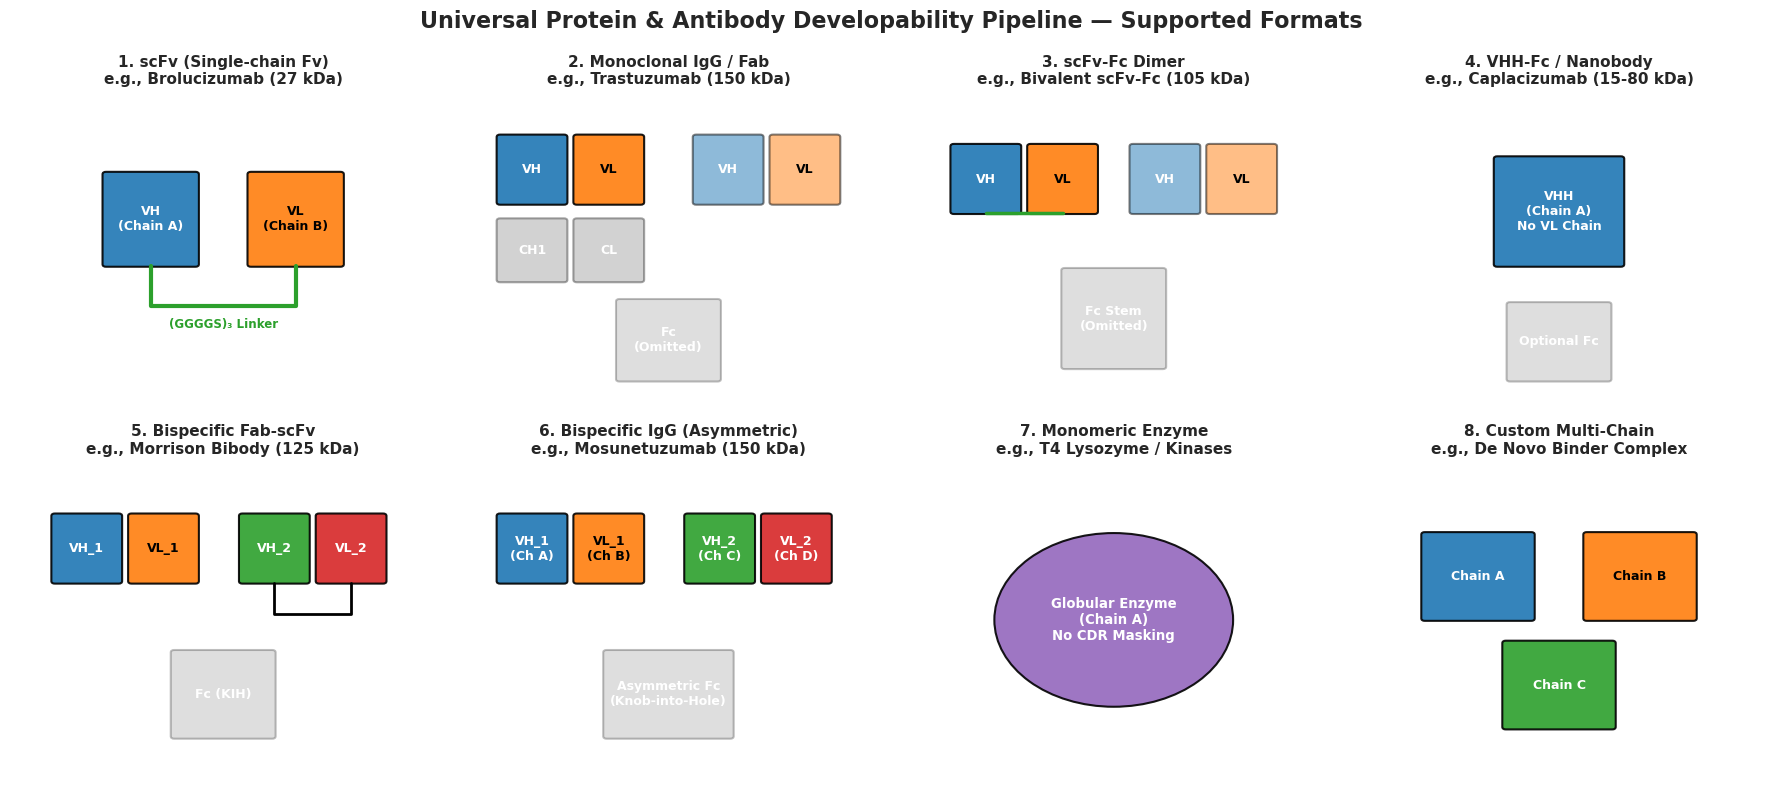

In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Universal Protein & Antibody Developability Pipeline — Supported Formats", fontsize=16, fontweight='bold', y=0.98)

def draw_domain(ax, x, y, w, h, label, color, ec='black', alpha=0.9):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", facecolor=color, edgecolor=ec, linewidth=1.5, alpha=alpha)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontweight='bold', fontsize=9, color='white' if color in ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#7f7f7f'] else 'black')

formats = [
    ("1. scFv (Single-chain Fv)\ne.g., Brolucizumab (27 kDa)", "scfv"),
    ("2. Monoclonal IgG / Fab\ne.g., Trastuzumab (150 kDa)", "igg"),
    ("3. scFv-Fc Dimer\ne.g., Bivalent scFv-Fc (105 kDa)", "scfv_fc"),
    ("4. VHH-Fc / Nanobody\ne.g., Caplacizumab (15-80 kDa)", "vhh"),
    ("5. Bispecific Fab-scFv\ne.g., Morrison Bibody (125 kDa)", "fab_scfv"),
    ("6. Bispecific IgG (Asymmetric)\ne.g., Mosunetuzumab (150 kDa)", "bs_igg"),
    ("7. Monomeric Enzyme\ne.g., T4 Lysozyme / Kinases", "enzyme"),
    ("8. Custom Multi-Chain\ne.g., De Novo Binder Complex", "custom")
]

for ax, (title, ftype) in zip(axes.flatten(), formats):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    
    if ftype == "scfv":
        draw_domain(ax, 2.2, 4.5, 2.2, 3.0, "VH\n(Chain A)", "#1f77b4")
        draw_domain(ax, 5.6, 4.5, 2.2, 3.0, "VL\n(Chain B)", "#ff7f0e")
        ax.plot([3.3, 3.3, 6.7, 6.7], [4.5, 3.2, 3.2, 4.5], color="#2ca02c", lw=3, label="Linker")
        ax.text(5.0, 2.5, "(GGGGS)₃ Linker", ha='center', fontsize=8.5, fontweight='bold', color="#2ca02c")
    elif ftype == "igg":
        # Left Fab + Right Fab + Fc (ghosted constant domains)
        draw_domain(ax, 1.0, 6.5, 1.6, 2.2, "VH", "#1f77b4")
        draw_domain(ax, 2.8, 6.5, 1.6, 2.2, "VL", "#ff7f0e")
        draw_domain(ax, 1.0, 4.0, 1.6, 2.0, "CH1", "#7f7f7f", alpha=0.35)
        draw_domain(ax, 2.8, 4.0, 1.6, 2.0, "CL", "#7f7f7f", alpha=0.35)
        draw_domain(ax, 5.6, 6.5, 1.6, 2.2, "VH", "#1f77b4", alpha=0.5)
        draw_domain(ax, 7.4, 6.5, 1.6, 2.2, "VL", "#ff7f0e", alpha=0.5)
        draw_domain(ax, 3.8, 0.8, 2.4, 2.6, "Fc\n(Omitted)", "#7f7f7f", alpha=0.25)
    elif ftype == "scfv_fc":
        draw_domain(ax, 1.2, 6.2, 1.6, 2.2, "VH", "#1f77b4")
        draw_domain(ax, 3.0, 6.2, 1.6, 2.2, "VL", "#ff7f0e")
        ax.plot([2.0, 3.8], [6.2, 6.2], color="#2ca02c", lw=2.5)
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH", "#1f77b4", alpha=0.5)
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL", "#ff7f0e", alpha=0.5)
        draw_domain(ax, 3.8, 1.2, 2.4, 3.2, "Fc Stem\n(Omitted)", "#7f7f7f", alpha=0.25)
    elif ftype == "vhh":
        draw_domain(ax, 3.5, 4.5, 3.0, 3.5, "VHH\n(Chain A)\nNo VL Chain", "#1f77b4")
        draw_domain(ax, 3.8, 0.8, 2.4, 2.5, "Optional Fc", "#7f7f7f", alpha=0.25)
    elif ftype == "fab_scfv":
        draw_domain(ax, 1.0, 6.2, 1.6, 2.2, "VH_1", "#1f77b4")
        draw_domain(ax, 2.8, 6.2, 1.6, 2.2, "VL_1", "#ff7f0e")
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH_2", "#2ca02c")
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL_2", "#d62728")
        ax.plot([6.2, 6.2, 8.0, 8.0], [6.2, 5.2, 5.2, 6.2], color="black", lw=2)
        draw_domain(ax, 3.8, 1.2, 2.4, 2.8, "Fc (KIH)", "#7f7f7f", alpha=0.25)
    elif ftype == "bs_igg":
        draw_domain(ax, 1.0, 6.2, 1.6, 2.2, "VH_1\n(Ch A)", "#1f77b4")
        draw_domain(ax, 2.8, 6.2, 1.6, 2.2, "VL_1\n(Ch B)", "#ff7f0e")
        draw_domain(ax, 5.4, 6.2, 1.6, 2.2, "VH_2\n(Ch C)", "#2ca02c")
        draw_domain(ax, 7.2, 6.2, 1.6, 2.2, "VL_2\n(Ch D)", "#d62728")
        draw_domain(ax, 3.5, 1.2, 3.0, 2.8, "Asymmetric Fc\n(Knob-into-Hole)", "#7f7f7f", alpha=0.25)
    elif ftype == "enzyme":
        circ = patches.Circle((5.0, 5.0), 2.8, facecolor="#9467bd", edgecolor="black", lw=1.5, alpha=0.9)
        ax.add_patch(circ)
        ax.text(5.0, 5.0, "Globular Enzyme\n(Chain A)\nNo CDR Masking", ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
    elif ftype == "custom":
        draw_domain(ax, 1.8, 5.0, 2.6, 2.8, "Chain A", "#1f77b4")
        draw_domain(ax, 5.6, 5.0, 2.6, 2.8, "Chain B", "#ff7f0e")
        draw_domain(ax, 3.7, 1.5, 2.6, 2.8, "Chain C", "#2ca02c")

plt.tight_layout()
plt.savefig("pipeline_protein_formats_overview.png", dpi=300)
plt.show()

# Evaluate New campaigns


 PROSPECTIVE TRIAGE: Campaign_scFvLA-L2K-1 (n = 1561 generated variants)
 -> Gate Pass Rate: 304 / 1561 (19.5%) passed all 3 biophysical gates.

--- SUMMARY BY SOURCE GENERATOR MODEL ---
                         total_variants gate_pass_rate  in_top_25_pct  median_agnostic_score  median_num_muts
source_model                                                                                                 
Consensus (Multi-Model)              49          59.2%             32               0.411638              1.0
ESMC                                226          28.3%             83              -0.112571              3.0
AntiFold                            250          20.4%             62              -0.214791              4.0
ProteinMPNN                         267          22.5%             76              -0.335168              4.0
SolubleMPNN                         275          16.4%             62              -0.523053              4.0
ThermoMPNN                          202   

/tmp/ipykernel_17705/976473909.py:297: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_17705/976473909.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


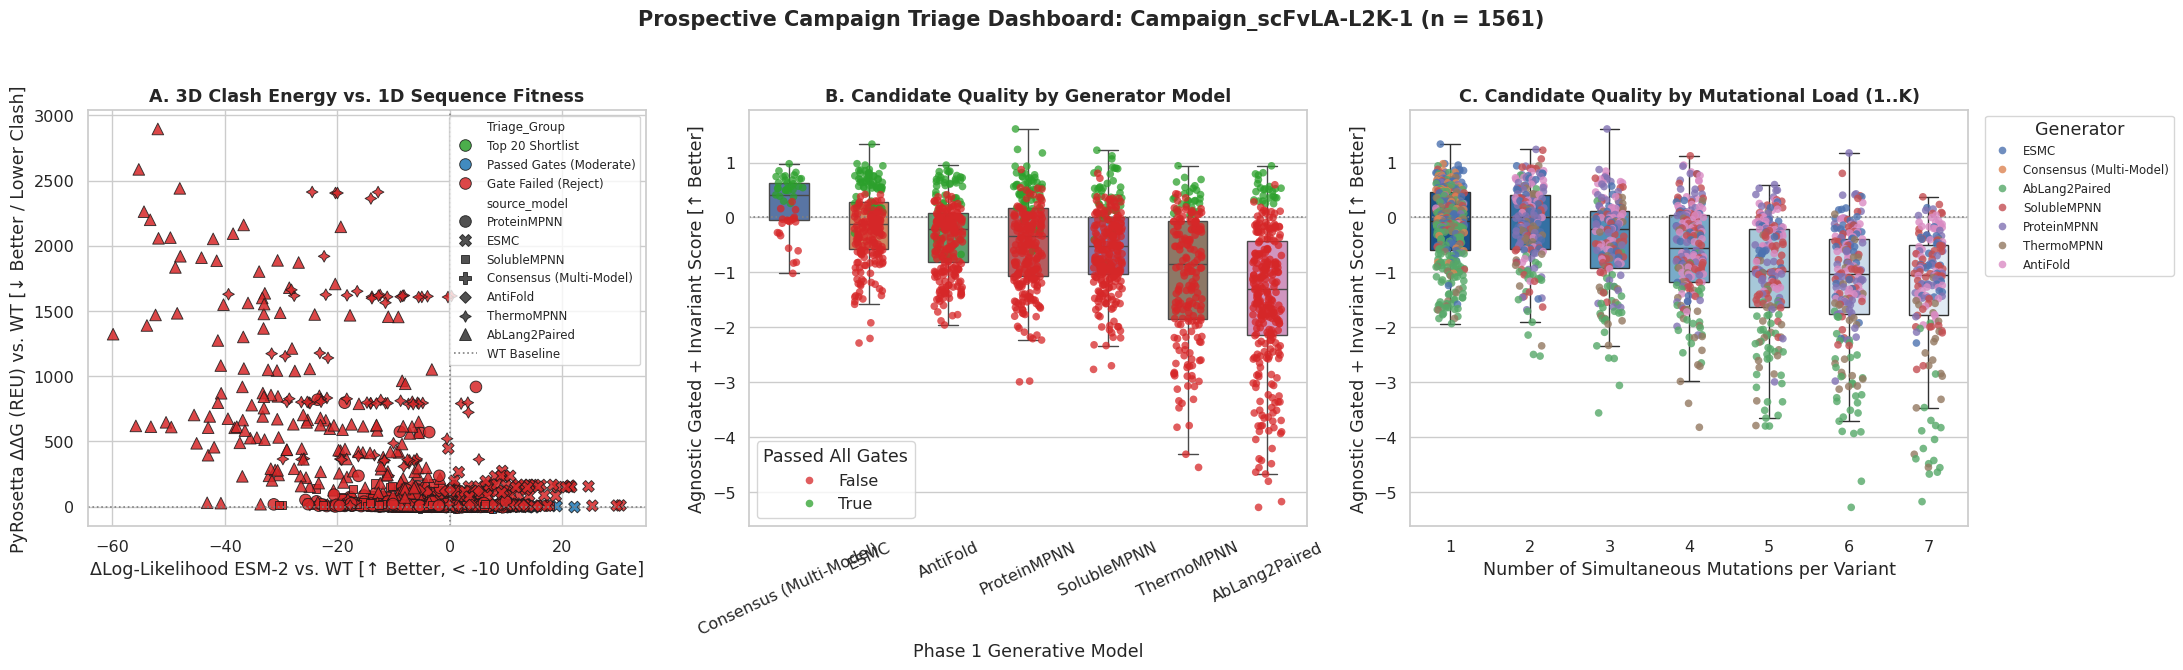

 -> Saved dashboard: prospective_triage_dashboard_Campaign_scFvLAL2K1.png


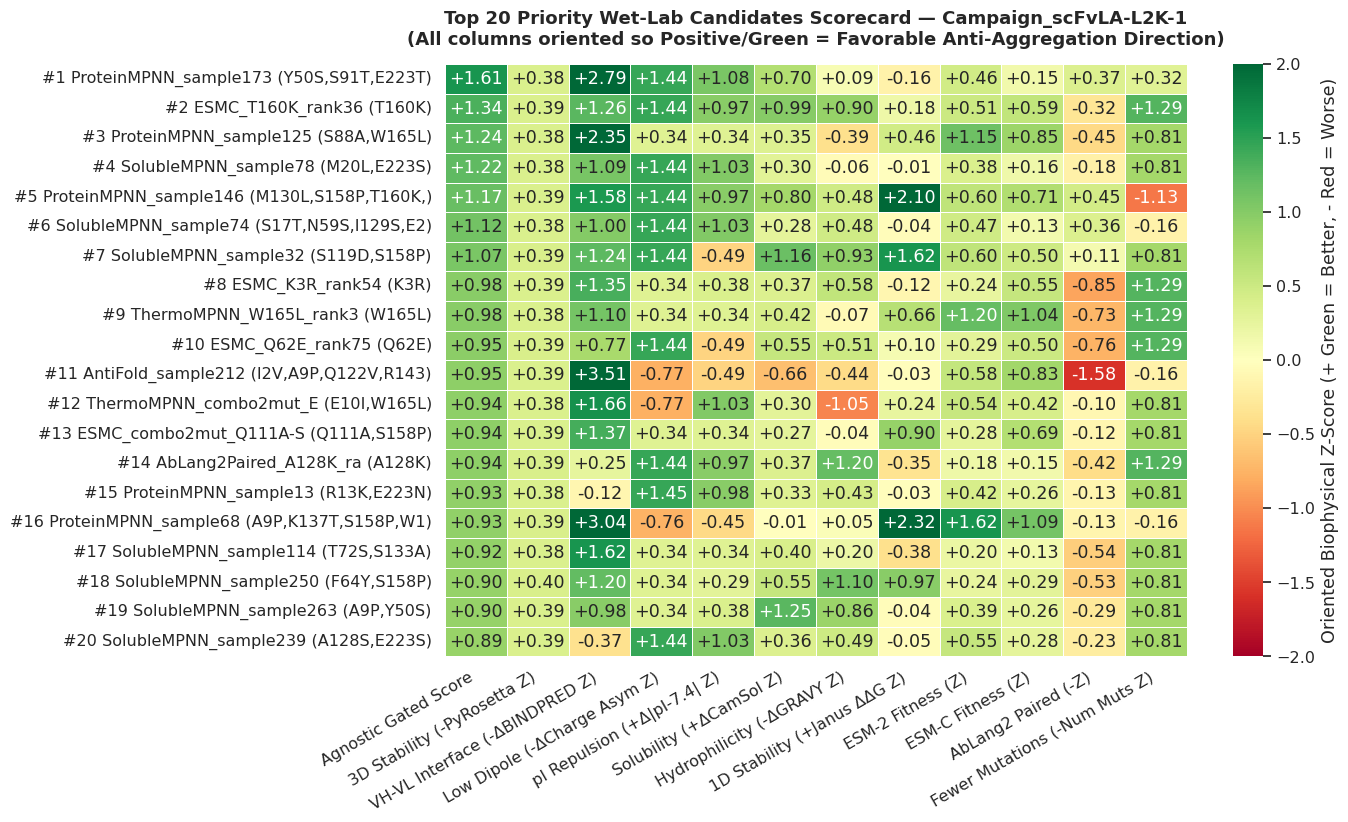

 -> Saved Top-20 scorecard heatmap: prospective_top20_scorecard_Campaign_scFvLAL2K1.png

--- IN-SILICO REGIME DIAGNOSTIC (nDCG@20 vs. 3D Physical Anchor) ---
 -> Agnostic Gated Score nDCG@20 (3D Anchor Alignment): 0.868
 -> Raw ESM-C Fitness    nDCG@20 (3D Anchor Alignment): 0.739
 -> [REGIME INSIGHT]: High PLM-vs-3D nDCG detected! This campaign behaves like CD3A (1D PLM fitness and 3D physics agree at the top of the funnel).

--- JACCARD SHORTLIST DIVERSITY CHECK (Top 20) ---
 -> Naive Top-20 Mean Pairwise Mutation Jaccard:       0.031 (Unique mutations covered: 33)
 -> Diversified Top-20 Mean Pairwise Mutation Jaccard: 0.024 (Unique mutations covered: 34)
 -> Saved Jaccard-Diversified Wet-Lab Shortlist: prospective_top20_jaccard_diversified_Campaign_scFvLAL2K1.csv


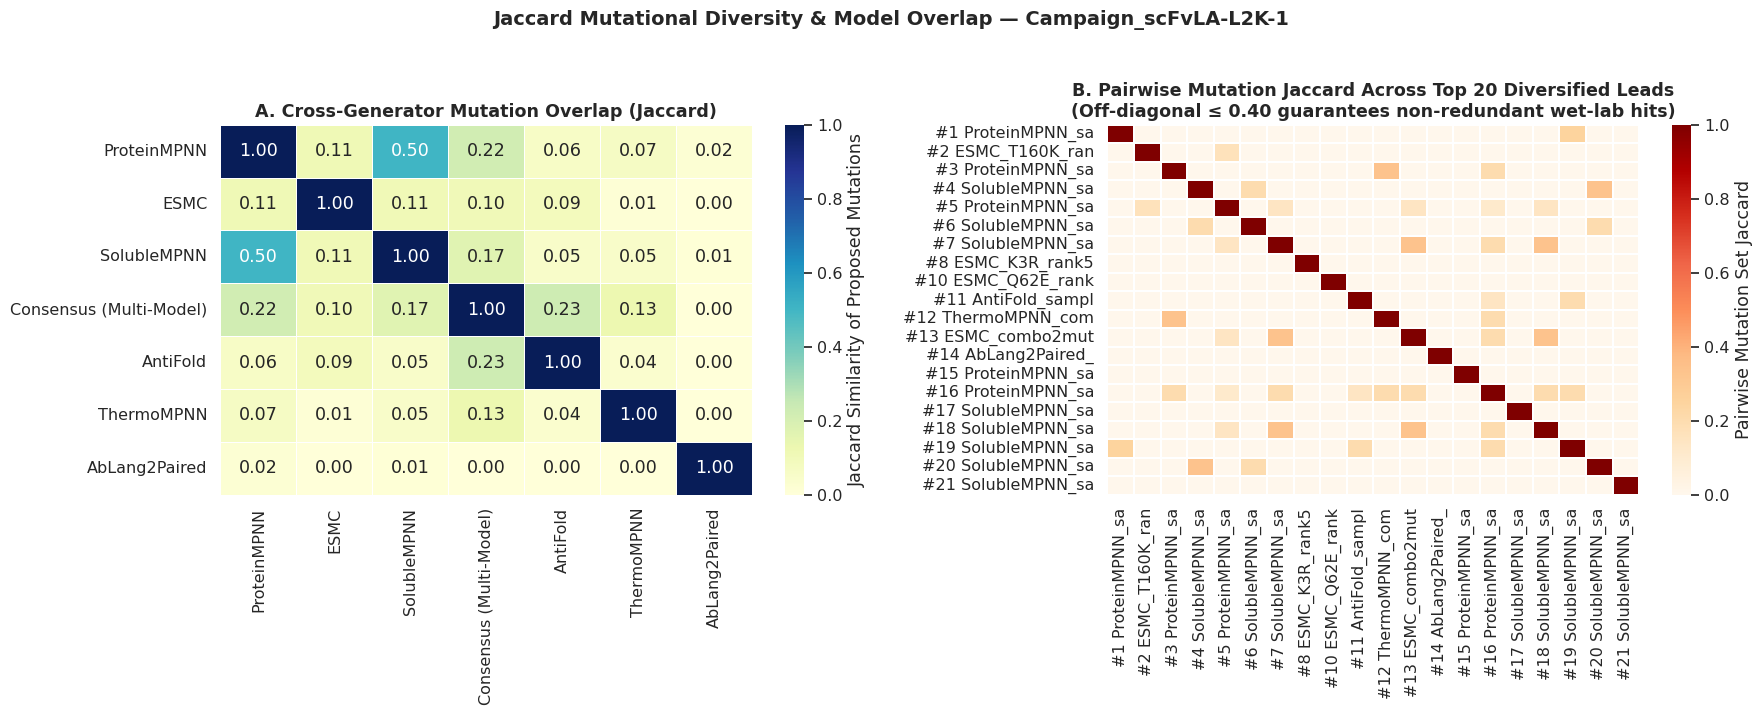

 -> Saved Jaccard diagnostics figure: prospective_jaccard_diagnostics_Campaign_scFvLAL2K1.png

 PROSPECTIVE TRIAGE: Campaign_scFvLA-L2K-2 (n = 1561 generated variants)
 -> Gate Pass Rate: 304 / 1561 (19.5%) passed all 3 biophysical gates.

--- SUMMARY BY SOURCE GENERATOR MODEL ---
                         total_variants gate_pass_rate  in_top_25_pct  median_agnostic_score  median_num_muts
source_model                                                                                                 
Consensus (Multi-Model)              49          59.2%             32               0.421515              1.0
ESMC                                226          28.3%             82              -0.155151              3.0
AntiFold                            250          20.4%             70              -0.178328              4.0
ProteinMPNN                         267          22.5%             77              -0.359049              4.0
SolubleMPNN                         275          16.4%    

/tmp/ipykernel_17705/976473909.py:297: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_17705/976473909.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


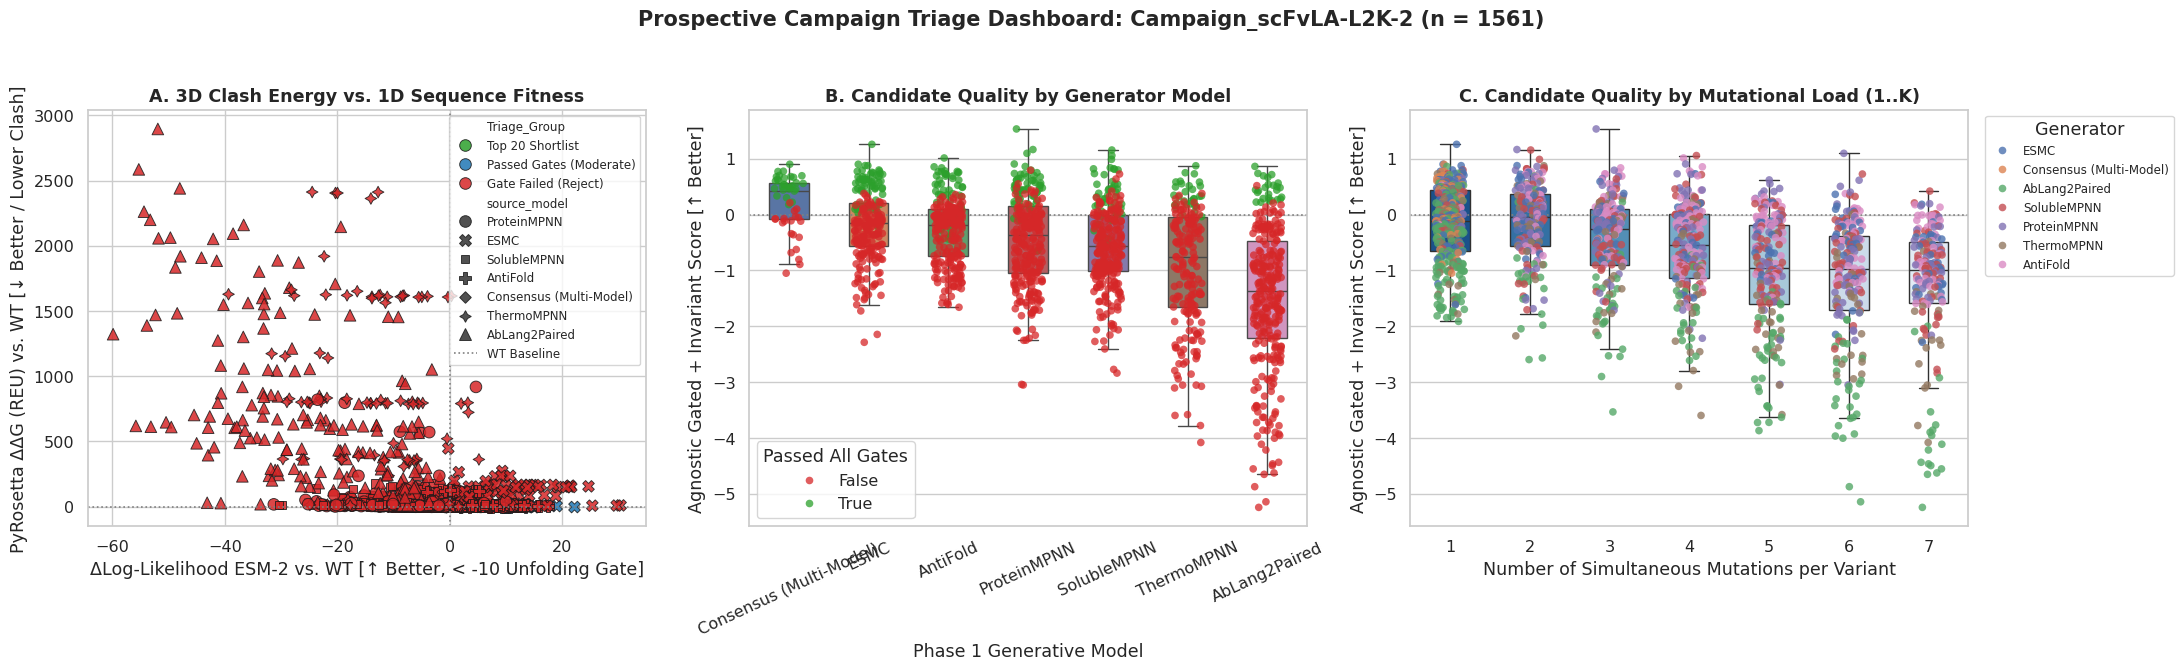

 -> Saved dashboard: prospective_triage_dashboard_Campaign_scFvLAL2K2.png


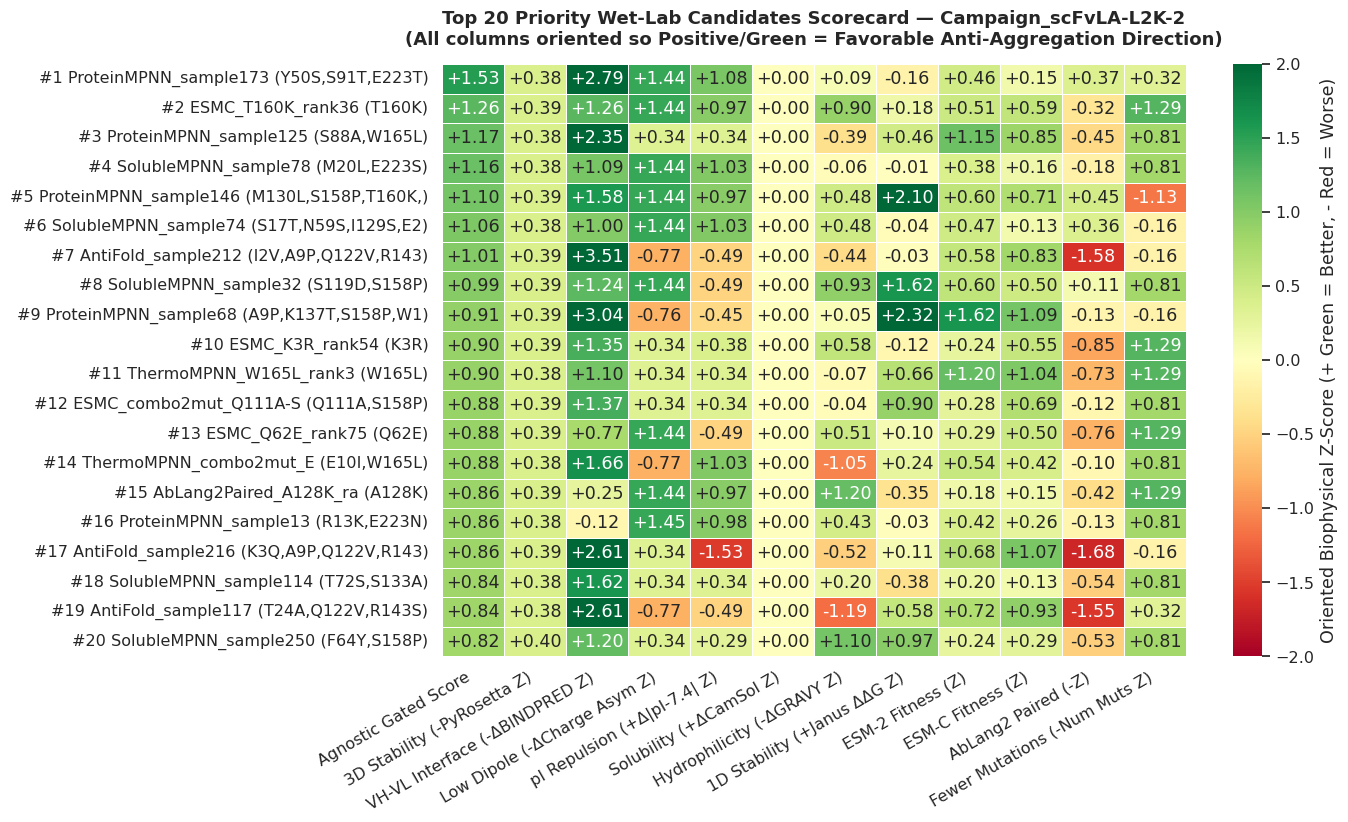

 -> Saved Top-20 scorecard heatmap: prospective_top20_scorecard_Campaign_scFvLAL2K2.png

--- IN-SILICO REGIME DIAGNOSTIC (nDCG@20 vs. 3D Physical Anchor) ---
 -> Agnostic Gated Score nDCG@20 (3D Anchor Alignment): 0.886
 -> Raw ESM-C Fitness    nDCG@20 (3D Anchor Alignment): 0.739
 -> [REGIME INSIGHT]: High PLM-vs-3D nDCG detected! This campaign behaves like CD3A (1D PLM fitness and 3D physics agree at the top of the funnel).

--- JACCARD SHORTLIST DIVERSITY CHECK (Top 20) ---
 -> Naive Top-20 Mean Pairwise Mutation Jaccard:       0.033 (Unique mutations covered: 34)
 -> Diversified Top-20 Mean Pairwise Mutation Jaccard: 0.026 (Unique mutations covered: 34)
 -> Saved Jaccard-Diversified Wet-Lab Shortlist: prospective_top20_jaccard_diversified_Campaign_scFvLAL2K2.csv


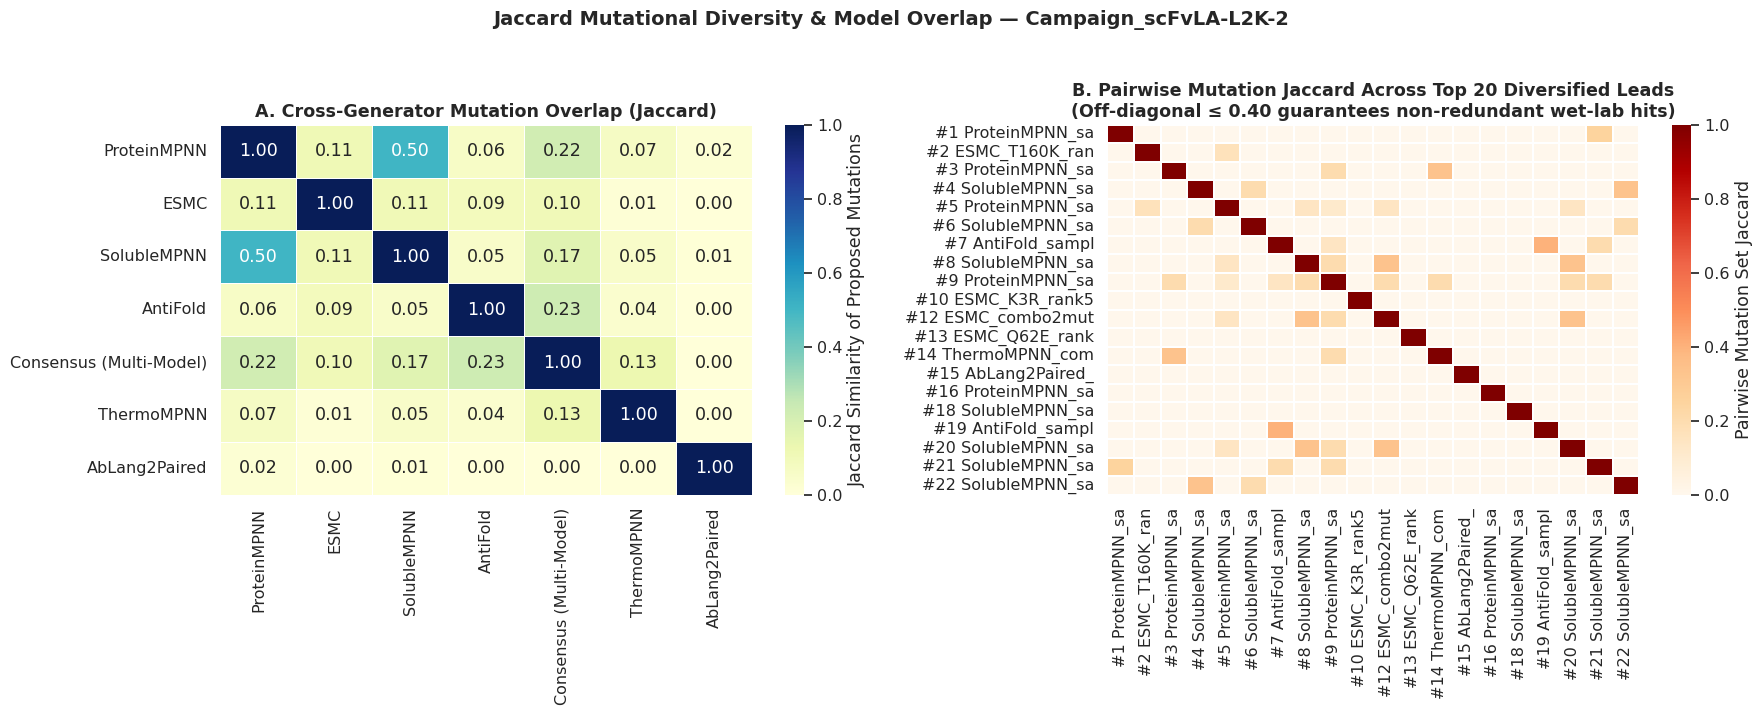

 -> Saved Jaccard diagnostics figure: prospective_jaccard_diagnostics_Campaign_scFvLAL2K2.png


In [4]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", font_scale=1.05)

# ==========================================
# 1. Input Phase 2 CSVs for Your New Campaigns
# ==========================================
# Replace with the paths to your two new Phase 2 scored CSV files
CAMPAIGN_CSVS = [
    ("Campaign_scFvLA-L2K-1", "scFvLA-L2K-updated_developability_metrics.csv"),
    ("Campaign_scFvLA-L2K-2", "scFvLA-L2K-updated-2_developability_metrics.csv"),
]

TOP_N_SHORTLIST = 20  # Number of top candidates to highlight and export per campaign

reverse_rename_map = {
    'ID': 'id', 'Sequence ID': 'id', 'Samples_ID': 'id',
    'Mutations': 'mutations',
    'Global Composite Score': 'global_composite_score',
    'Stability ΔΔG (Janus)': 'janus_ddg',
    'Stability ΔΔG (PyRosetta)': 'pyrosetta_ddg',
    'Intrinsic Solubility (CamSol)': 'camsol_score',
    'Isoelectric Point (pI)': 'pI',
    'Hydrophobicity Index (GRAVY)': 'gravy',
    'Net Charge (pH 7.4)': 'net_charge',
    'VH-VL Charge Delta': 'charge_asymmetry',
    'Affinity Log10 Kd (BINDPRED)': 'bindpred_kd',
    'ΔLog-Likelihood (ESM-2 General)': 'esm_fitness',
    'ΔLog-Likelihood (ESM-C)': 'esmc_fitness',
    'ΔLog-Likelihood (AntiBERTy)': 'antiberty_fitness',
    'ΔLog-Likelihood (AbLang2 Paired)': 'ablang_fitness',
    'ΔLog-Likelihood (ProtBERT)': 'protbert_fitness',
    'VH Sequence': 'VH', 'VL Sequence': 'VL'
}

def count_muts(m):
    m_str = str(m).strip()
    if m_str in ['WT', 'nan', 'None', '']:
        return 0
    return len([x for x in m_str.split(',') if x.strip()])

def extract_source_model(seq_id: str) -> str:
    s = str(seq_id).strip()
    if s.endswith("_WT") or s == "WT":
        return "WT"
    if "+" in s:
        return "Consensus (Multi-Model)"
    prefix = s.split("_")[0]
    known_prefixes = [
        "AntiFold", "ProteinMPNN", "SolubleMPNN", 
        "ThermoMPNN", "ESMC", "AbLang2Paired"
    ]
    for kp in known_prefixes:
        if prefix.lower().startswith(kp.lower()):
            return kp
    return prefix


# ==========================================
# 2. Prospective Evaluation Function
# ==========================================
def evaluate_prospective_campaign(campaign_name: str, csv_path: str):
    if not os.path.exists(csv_path):
        print(f" -> File not found: {csv_path}. Skipping {campaign_name}.")
        return None

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    df = df.rename(columns=reverse_rename_map)

    if 'pI' in df.columns:
        df['pi_delta'] = (df['pI'] - 7.4).abs()
    df['num_mutations'] = df['mutations'].apply(count_muts)
    df['source_model'] = df['id'].apply(extract_source_model)
    df['is_consensus'] = df['id'].astype(str).str.contains(r'\+')

    # Locate the WT baseline row
    wt_mask = (
        (df['mutations'].astype(str).str.strip() == 'WT') |
        (df['id'].astype(str).str.endswith('_WT')) |
        (df['num_mutations'] == 0)
    )
    if not wt_mask.any():
        raise ValueError(f"No WT baseline row found in {csv_path}!")

    wt_row = df[wt_mask].iloc[0]
    mut_df = df[~wt_mask].copy().reset_index(drop=True)

    print(f"\n{'='*85}")
    print(f" PROSPECTIVE TRIAGE: {campaign_name} (n = {len(mut_df)} generated variants)")
    print(f"{'='*85}")

    # ---------------------------------------------------------
    # STEP 1: Compute Raw Deltas Relative to WT
    # ---------------------------------------------------------
    intrinsic_cols = [
        'camsol_score', 'gravy', 'charge_asymmetry', 
        'bindpred_kd', 'pi_delta', 'net_charge'
    ]
    already_relative_cols = [
        'janus_ddg', 'pyrosetta_ddg', 'esm_fitness', 'esmc_fitness', 
        'antiberty_fitness', 'ablang_fitness', 'protbert_fitness', 'num_mutations'
    ]

    for col in intrinsic_cols:
        if col in mut_df.columns and pd.notna(wt_row.get(col, np.nan)):
            mut_df[f'delta_{col}'] = mut_df[col] - float(wt_row[col])
        else:
            mut_df[f'delta_{col}'] = 0.0

    for col in already_relative_cols:
        if col not in mut_df.columns:
            mut_df[col] = 0.0
        elif col != 'num_mutations' and pd.notna(wt_row.get(col, np.nan)) and float(wt_row[col]) != 0.0:
            # Ensure relative metrics are anchored at 0.0 for WT
            mut_df[col] = mut_df[col] - float(wt_row[col])

    all_feature_cols = [f'delta_{c}' for c in intrinsic_cols] + already_relative_cols
    for col in all_feature_cols:
        mut_df[f'raw_{col}'] = mut_df[col].fillna(0.0)

    # Count how many physical dimensions strictly improve or maintain WT baseline
    mut_df['wt_improvements_count'] = (
        (mut_df['raw_pyrosetta_ddg'] <= 0.0).astype(int) +
        (mut_df['raw_delta_bindpred_kd'] <= 0.0).astype(int) +
        (mut_df['raw_delta_charge_asymmetry'] <= 0.0).astype(int) +
        (mut_df['raw_delta_pi_delta'] >= 0.0).astype(int) +
        (mut_df['raw_delta_camsol_score'] >= 0.0).astype(int) +
        (mut_df['raw_delta_gravy'] <= 0.0).astype(int)
    )

    # ---------------------------------------------------------
    # STEP 2: One-Sided Downside Hinges & Within-Campaign Z-Scores
    # ---------------------------------------------------------
    mut_df['hinge_esm']    = np.minimum(0.0, mut_df['raw_esm_fitness'])
    mut_df['hinge_janus']  = np.minimum(0.0, mut_df['raw_janus_ddg'])
    mut_df['hinge_camsol'] = np.minimum(0.0, mut_df['raw_delta_camsol_score'])

    scaler = StandardScaler()
    cols_to_scale = all_feature_cols + ['hinge_esm', 'hinge_janus', 'hinge_camsol']

    for col in cols_to_scale:
        z_col = f'z_{col}'
        valid_idx = mut_df[col].dropna().index
        if len(valid_idx) > 1 and mut_df.loc[valid_idx, col].nunique() > 1:
            mut_df.loc[valid_idx, z_col] = scaler.fit_transform(
                mut_df.loc[valid_idx, [col]]
            ).flatten()
        else:
            mut_df[z_col] = 0.0

    # ---------------------------------------------------------
    # STEP 3: Non-Compensatory Hard Gates & Agnostic Score
    # ---------------------------------------------------------
    # Gate 1: 3D Steric Clash Gate (Worst 25% Z-tail AND positive clash energy, or > +5 REU)
    clash_fail = ((mut_df['z_pyrosetta_ddg'] > 0.67) & (mut_df['raw_pyrosetta_ddg'] > 0.0)) | (mut_df['raw_pyrosetta_ddg'] > 5.0)

    # Gate 2: VH-VL Interface Gate (Worst 25% Z-tail AND weakened Kd relative to WT)
    interface_fail = (mut_df['z_delta_bindpred_kd'] > 0.67) & (mut_df['raw_delta_bindpred_kd'] > 0.0)

    # Gate 3: 1D Unfolding Gate (Severe drop in evolutionary likelihood or folding stability)
    unfold_fail = (mut_df['raw_esm_fitness'] < -10.0) | (mut_df['raw_janus_ddg'] < -0.5)

    mut_df['passed_all_gates'] = ~(clash_fail | interface_fail | unfold_fail)

    def build_gate_status(row_idx):
        reasons = []
        if clash_fail.iloc[row_idx]:     reasons.append("3D_Clash")
        if interface_fail.iloc[row_idx]: reasons.append("Interface_Kd")
        if unfold_fail.iloc[row_idx]:    reasons.append("1D_Unfolding")
        return "PASS" if not reasons else "FAIL (" + "+".join(reasons) + ")"

    mut_df['gate_status'] = [build_gate_status(i) for i in range(len(mut_df))]

    # Component A: Directionally Invariant 3D & Electrostatic Core
    invariant_core = (
        -0.30 * mut_df['z_pyrosetta_ddg'] +
        -0.25 * mut_df['z_delta_bindpred_kd'] +
        -0.20 * mut_df['z_delta_charge_asymmetry'] +
        +0.15 * mut_df['z_delta_pi_delta'] +
        -0.10 * mut_df['z_num_mutations']
    )

    # Component B: Downside 1D Folding Hinge (Penalizes < 0 vs WT; ignores > 0 consensus inflation)
    downside_folding_hinge = (
        +0.25 * mut_df['z_hinge_esm'] +
        +0.15 * mut_df['z_hinge_janus'] +
        +0.10 * mut_df['z_hinge_camsol']
    )

    # Component C: Non-Compensatory Gate Penalty
    gate_penalty = -0.50 * (
        clash_fail.astype(float) + interface_fail.astype(float) + unfold_fail.astype(float)
    )

    mut_df['agnostic_gated_score'] = invariant_core + downside_folding_hinge + gate_penalty

    # Assign Prospective Triage Tiers
    tier_labels = ['Bottom 25%\n(High Risk / Reject)', 'Middle 50%\n(Moderate)', 'Top 25%\n(Priority Leads)']
    mut_df['Prospective_Tier'] = pd.qcut(
        mut_df['agnostic_gated_score'].rank(method='first'),
        q=[0, 0.25, 0.75, 1.0],
        labels=tier_labels
    )

    # Rank candidates (Gate-passers first, then highest agnostic_gated_score)
    mut_df = mut_df.sort_values(
        by=['passed_all_gates', 'agnostic_gated_score'],
        ascending=[False, False]
    ).reset_index(drop=True)
    mut_df['prospective_rank'] = np.arange(1, len(mut_df) + 1)

    # ---------------------------------------------------------
    # STEP 4: Console Summaries & CSV Exports
    # ---------------------------------------------------------
    print(f" -> Gate Pass Rate: {mut_df['passed_all_gates'].sum()} / {len(mut_df)} "
          f"({100.0 * mut_df['passed_all_gates'].mean():.1f}%) passed all 3 biophysical gates.")

    print("\n--- SUMMARY BY SOURCE GENERATOR MODEL ---")
    model_summary = mut_df.groupby('source_model').agg(
        total_variants=('id', 'count'),
        gate_pass_rate=('passed_all_gates', lambda s: f"{100*s.mean():.1f}%"),
        in_top_25_pct=('Prospective_Tier', lambda s: (s == 'Top 25%\n(Priority Leads)').sum()),
        median_agnostic_score=('agnostic_gated_score', 'median'),
        median_num_muts=('raw_num_mutations', 'median')
    ).sort_values(by='median_agnostic_score', ascending=False)
    print(model_summary.to_string())

    print("\n--- SUMMARY BY MUTATION COUNT (1 .. K) ---")
    mut_count_summary = mut_df.groupby('raw_num_mutations').agg(
        variants=('id', 'count'),
        gate_pass_rate=('passed_all_gates', lambda s: f"{100*s.mean():.1f}%"),
        median_agnostic_score=('agnostic_gated_score', 'median'),
        median_pyrosetta_ddg=('raw_pyrosetta_ddg', 'median'),
        median_esm_fitness=('raw_esm_fitness', 'median')
    )
    print(mut_count_summary.to_string())

    summary_cols = [
        'prospective_rank', 'id', 'source_model', 'mutations', 'raw_num_mutations',
        'agnostic_gated_score', 'Prospective_Tier', 'gate_status', 'wt_improvements_count',
        'raw_pyrosetta_ddg', 'raw_delta_bindpred_kd', 'raw_delta_charge_asymmetry',
        'raw_delta_pi_delta', 'raw_delta_camsol_score', 'raw_delta_gravy',
        'raw_janus_ddg', 'raw_esm_fitness', 'raw_esmc_fitness', 'raw_ablang_fitness'
    ]
    summary_cols = [c for c in summary_cols if c in mut_df.columns]

    print(f"\n--- TOP {min(TOP_N_SHORTLIST, len(mut_df))} PRIORITY WET-LAB CANDIDATES ({campaign_name}) ---")
    print(mut_df[summary_cols].head(TOP_N_SHORTLIST).to_string(index=False))

    clean_tag = re.sub(r'\W+', '', campaign_name)
    full_out_csv = f"prospective_ranked_all_{clean_tag}.csv"
    top_out_csv = f"prospective_top{TOP_N_SHORTLIST}_shortlist_{clean_tag}.csv"
    mut_df.to_csv(full_out_csv, index=False)
    mut_df[summary_cols].head(TOP_N_SHORTLIST).to_csv(top_out_csv, index=False)
    print(f"\n -> Saved full ranked table: {full_out_csv}")
    print(f" -> Saved Top-{TOP_N_SHORTLIST} wet-lab shortlist: {top_out_csv}")

    # =========================================================
    # FIGURE 1: 3-Panel Prospective Diagnostic Dashboard
    # =========================================================
    fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
    plt.subplots_adjust(wspace=0.28)

    # Panel A: 3D PyRosetta Energy vs. 1D ESM-2 Fitness (Gate & Pareto Map)
    ax1 = axes[0]
    mut_df['Triage_Group'] = np.where(
        ~mut_df['passed_all_gates'], 'Gate Failed (Reject)',
        np.where(mut_df['prospective_rank'] <= TOP_N_SHORTLIST, f'Top {TOP_N_SHORTLIST} Shortlist', 'Passed Gates (Moderate)')
    )
    group_palette = {
        f'Top {TOP_N_SHORTLIST} Shortlist': '#2ca02c',
        'Passed Gates (Moderate)': '#1f77b4',
        'Gate Failed (Reject)': '#d62728'
    }
    sns.scatterplot(
        data=mut_df, x='raw_esm_fitness', y='raw_pyrosetta_ddg',
        hue='Triage_Group', style='source_model', palette=group_palette,
        s=70, alpha=0.85, edgecolor='k', ax=ax1
    )
    ax1.axhline(0, color='gray', linestyle=':', linewidth=1.2, label='WT Baseline')
    ax1.axvline(0, color='gray', linestyle=':', linewidth=1.2)
    ax1.set_title("A. 3D Clash Energy vs. 1D Sequence Fitness", fontweight='bold')
    ax1.set_xlabel("ΔLog-Likelihood ESM-2 vs. WT [↑ Better, < -10 Unfolding Gate]")
    ax1.set_ylabel("PyRosetta ΔΔG (REU) vs. WT [↓ Better / Lower Clash]")
    ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper right', fontsize=8.5, frameon=True)

    # Panel B: Agnostic Gated Score by Generative Model
    ax2 = axes[1]
    model_order = model_summary.index.tolist()
    sns.boxplot(
        data=mut_df, x='source_model', y='agnostic_gated_score', order=model_order,
        palette='deep', showfliers=False, width=0.5, ax=ax2
    )
    sns.stripplot(
        data=mut_df, x='source_model', y='agnostic_gated_score', order=model_order,
        hue='passed_all_gates', palette={True: '#2ca02c', False: '#d62728'},
        dodge=False, alpha=0.75, jitter=0.18, size=5.5, ax=ax2
    )
    ax2.axhline(0, color='gray', linestyle=':', linewidth=1.2)
    ax2.set_title("B. Candidate Quality by Generator Model", fontweight='bold')
    ax2.set_xlabel("Phase 1 Generative Model")
    ax2.set_ylabel("Agnostic Gated + Invariant Score [↑ Better]")
    ax2.tick_params(axis='x', rotation=25)
    ax2.legend(title='Passed All Gates', loc='lower left', frameon=True)

    # Panel C: Agnostic Gated Score Across Mutation Counts (1 .. max_muts)
    ax3 = axes[2]
    sns.boxplot(
        data=mut_df, x='raw_num_mutations', y='agnostic_gated_score',
        palette='Blues_r', showfliers=False, width=0.5, ax=ax3
    )
    sns.stripplot(
        data=mut_df, x='raw_num_mutations', y='agnostic_gated_score',
        hue='source_model', palette='deep', dodge=False, alpha=0.8, jitter=0.18, size=5.5, ax=ax3
    )
    ax3.axhline(0, color='gray', linestyle=':', linewidth=1.2)
    ax3.set_title("C. Candidate Quality by Mutational Load (1..K)", fontweight='bold')
    ax3.set_xlabel("Number of Simultaneous Mutations per Variant")
    ax3.set_ylabel("Agnostic Gated + Invariant Score [↑ Better]")
    ax3.legend(title='Generator', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=8.5)

    fig.suptitle(f"Prospective Campaign Triage Dashboard: {campaign_name} (n = {len(mut_df)})", fontsize=15, fontweight='bold', y=1.03)
    plt.tight_layout()
    dash_file = f"prospective_triage_dashboard_{clean_tag}.png"
    plt.savefig(dash_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved dashboard: {dash_file}")

    # =========================================================
    # FIGURE 2: Top-N Candidates Biophysical Scorecard Heatmap
    # =========================================================
    top_df = mut_df.head(TOP_N_SHORTLIST).copy()
    top_df['Candidate_Label'] = (
        "#" + top_df['prospective_rank'].astype(str) + " " +
        top_df['id'].astype(str).str.slice(0, 22) + " (" +
        top_df['mutations'].astype(str).str.slice(0, 18) + ")"
    )

    # Orient all Z-scores so POSITIVE (+, Green) ALWAYS means BETTER biophysics
    scorecard_specs = [
        ('agnostic_gated_score',         +1.0, 'Agnostic Gated Score'),
        ('z_pyrosetta_ddg',              -1.0, '3D Stability (-PyRosetta Z)'),
        ('z_delta_bindpred_kd',          -1.0, 'VH-VL Interface (-ΔBINDPRED Z)'),
        ('z_delta_charge_asymmetry',     -1.0, 'Low Dipole (-ΔCharge Asym Z)'),
        ('z_delta_pi_delta',             +1.0, 'pI Repulsion (+Δ|pI-7.4| Z)'),
        ('z_delta_camsol_score',         +1.0, 'Solubility (+ΔCamSol Z)'),
        ('z_delta_gravy',                -1.0, 'Hydrophilicity (-ΔGRAVY Z)'),
        ('z_janus_ddg',                  +1.0, '1D Stability (+Janus ΔΔG Z)'),
        ('z_esm_fitness',                +1.0, 'ESM-2 Fitness (Z)'),
        ('z_esmc_fitness',               +1.0, 'ESM-C Fitness (Z)'),
        ('z_ablang_fitness',             -1.0, 'AbLang2 Paired (-Z)'),
        ('z_num_mutations',              -1.0, 'Fewer Mutations (-Num Muts Z)')
    ]

    heatmap_data = pd.DataFrame(index=top_df['Candidate_Label'])
    for col, sign_dir, clean_label in scorecard_specs:
        if col in top_df.columns:
            heatmap_data[clean_label] = sign_dir * top_df[col].values

    plt.figure(figsize=(14, max(6, 0.42 * len(top_df))))
    sns.heatmap(
        heatmap_data, annot=True, fmt="+.2f", cmap="RdYlGn", vmin=-2.0, vmax=2.0,
        linewidths=0.5, cbar_kws={"label": "Oriented Biophysical Z-Score (+ Green = Better, - Red = Worse)"}
    )
    plt.title(
        f"Top {len(top_df)} Priority Wet-Lab Candidates Scorecard — {campaign_name}\n"
        f"(All columns oriented so Positive/Green = Favorable Anti-Aggregation Direction)",
        fontweight='bold', fontsize=13, pad=14
    )
    plt.ylabel("")
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    scorecard_file = f"prospective_top{TOP_N_SHORTLIST}_scorecard_{clean_tag}.png"
    plt.savefig(scorecard_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved Top-{TOP_N_SHORTLIST} scorecard heatmap: {scorecard_file}")

    # =========================================================
    # STEP 5: JACCARD SIMILARITY & IN-SILICO nDCG@K DIAGNOSTICS
    # =========================================================
    def parse_mutation_set(mut_str: str) -> set:
        s = str(mut_str).strip()
        if s in ['WT', 'nan', 'None', '']:
            return set()
        return {tok.strip() for tok in s.split(',') if tok.strip()}

    def jaccard_sim(set_a: set, set_b: set) -> float:
        if not set_a and not set_b:
            return 1.0
        union_len = len(set_a | set_b)
        return len(set_a & set_b) / union_len if union_len > 0 else 0.0

    def compute_ndcg_at_k(pred_scores: np.ndarray, true_relevance: np.ndarray, k: int = 20) -> float:
        """Computes nDCG@K given predicted ranking scores and non-negative relevance [0..1]."""
        k = min(k, len(pred_scores))
        if k <= 0:
            return np.nan
        order_pred = np.argsort(pred_scores)[::-1][:k]
        order_ideal = np.argsort(true_relevance)[::-1][:k]
        discounts = np.log2(np.arange(2, k + 2))
        dcg = np.sum(true_relevance[order_pred] / discounts)
        idcg = np.sum(true_relevance[order_ideal] / discounts)
        return float(dcg / idcg) if idcg > 0 else 0.0

    mut_df['mut_set'] = mut_df['mutations'].apply(parse_mutation_set)

    # 1. In-Silico Pillar Agreement nDCG@20 (Diagnose CD3A vs. SP34 Regime on Unknown Family)
    # Define 3D physical relevance [0..1] from invariant 3D stability (-PyRosetta - BINDPRED)
    phys_3d_signal = -0.5 * mut_df['z_pyrosetta_ddg'].values - 0.5 * mut_df['z_delta_bindpred_kd'].values
    phys_rel = (phys_3d_signal - phys_3d_signal.min()) / (np.ptp(phys_3d_signal) + 1e-9)

    k_eval = min(TOP_N_SHORTLIST, len(mut_df))
    ndcg_agnostic_vs_3d = compute_ndcg_at_k(mut_df['agnostic_gated_score'].values, phys_rel, k=k_eval)
    ndcg_plm_vs_3d      = compute_ndcg_at_k(mut_df['z_esmc_fitness'].values, phys_rel, k=k_eval)

    print(f"\n--- IN-SILICO REGIME DIAGNOSTIC (nDCG@{k_eval} vs. 3D Physical Anchor) ---")
    print(f" -> Agnostic Gated Score nDCG@{k_eval} (3D Anchor Alignment): {ndcg_agnostic_vs_3d:.3f}")
    print(f" -> Raw ESM-C Fitness    nDCG@{k_eval} (3D Anchor Alignment): {ndcg_plm_vs_3d:.3f}")
    if ndcg_plm_vs_3d < 0.55:
        print(" -> [REGIME INSIGHT]: Low PLM-vs-3D nDCG detected! This campaign behaves like SP34 "
              "(1D PLM consensus conflicts with 3D packing). Rely on the Agnostic Gated Score.")
    else:
        print(" -> [REGIME INSIGHT]: High PLM-vs-3D nDCG detected! This campaign behaves like CD3A "
              "(1D PLM fitness and 3D physics agree at the top of the funnel).")

    # 2. Greedy Jaccard Diversity Pruning for Wet-Lab Shortlist
    # Prevents a single dominant point mutation from appearing in 15+ multi-mutant combinations
    MAX_MUTATION_JACCARD = 0.40  # Max allowed mutation-set overlap between any two shortlisted variants
    diversified_indices = []
    diversified_sets = []

    # First pass: select gate-passing candidates greedily by rank if Jaccard <= MAX_MUTATION_JACCARD
    for idx, row in mut_df[mut_df['passed_all_gates']].iterrows():
        m_set = row['mut_set']
        if not m_set:
            continue
        max_overlap = max([jaccard_sim(m_set, sel_set) for sel_set in diversified_sets], default=0.0)
        if max_overlap <= MAX_MUTATION_JACCARD:
            diversified_indices.append(idx)
            diversified_sets.append(m_set)
        if len(diversified_indices) >= TOP_N_SHORTLIST:
            break

    # If strict Jaccard pruning yielded fewer than TOP_N_SHORTLIST, backfill with highest remaining gate-passers
    if len(diversified_indices) < TOP_N_SHORTLIST:
        for idx in mut_df[mut_df['passed_all_gates']].index:
            if idx not in diversified_indices:
                diversified_indices.append(idx)
            if len(diversified_indices) >= TOP_N_SHORTLIST:
                break

    div_shortlist_df = mut_df.loc[diversified_indices].copy()
    div_shortlist_df['diversified_rank'] = np.arange(1, len(div_shortlist_df) + 1)

    # Compare Naive Top-K vs. Jaccard-Diversified Top-K
    naive_top_sets = mut_df.head(k_eval)['mut_set'].tolist()
    naive_mean_j = np.mean([
        jaccard_sim(naive_top_sets[i], naive_top_sets[j])
        for i in range(len(naive_top_sets)) for j in range(i + 1, len(naive_top_sets))
    ]) if len(naive_top_sets) > 1 else 0.0

    div_top_sets = div_shortlist_df['mut_set'].tolist()
    div_mean_j = np.mean([
        jaccard_sim(div_top_sets[i], div_top_sets[j])
        for i in range(len(div_top_sets)) for j in range(i + 1, len(div_top_sets))
    ]) if len(div_top_sets) > 1 else 0.0

    print(f"\n--- JACCARD SHORTLIST DIVERSITY CHECK (Top {len(div_shortlist_df)}) ---")
    print(f" -> Naive Top-{k_eval} Mean Pairwise Mutation Jaccard:       {naive_mean_j:.3f} "
          f"(Unique mutations covered: {len(set().union(*naive_top_sets) if naive_top_sets else set())})")
    print(f" -> Diversified Top-{len(div_shortlist_df)} Mean Pairwise Mutation Jaccard: {div_mean_j:.3f} "
          f"(Unique mutations covered: {len(set().union(*div_top_sets) if div_top_sets else set())})")

    div_csv = f"prospective_top{TOP_N_SHORTLIST}_jaccard_diversified_{clean_tag}.csv"
    div_shortlist_df[summary_cols].to_csv(div_csv, index=False)
    print(f" -> Saved Jaccard-Diversified Wet-Lab Shortlist: {div_csv}")

    # =========================================================
    # FIGURE 3: Jaccard Similarity Diagnostics (Cross-Model & Shortlist)
    # =========================================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    plt.subplots_adjust(wspace=0.32)

    # Panel A: Cross-Generator Mutational Footprint Jaccard Similarity
    models_present = [m for m in mut_df['source_model'].unique() if m != 'WT']
    model_mut_footprints = {
        m: set().union(*mut_df[mut_df['source_model'] == m]['mut_set'].tolist())
        for m in models_present
    }
    model_j_matrix = pd.DataFrame(index=models_present, columns=models_present, dtype=float)
    for m1 in models_present:
        for m2 in models_present:
            model_j_matrix.loc[m1, m2] = jaccard_sim(model_mut_footprints[m1], model_mut_footprints[m2])

    sns.heatmap(
        model_j_matrix, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
        linewidths=0.5, cbar_kws={"label": "Jaccard Similarity of Proposed Mutations"}, ax=axes[0]
    )
    axes[0].set_title("A. Cross-Generator Mutation Overlap (Jaccard)", fontweight='bold')

    # Panel B: Pairwise Mutation Jaccard Among Top Diversified Leads
    n_div = len(div_shortlist_df)
    div_labels = [f"#{r} {cid[:14]}" for r, cid in zip(div_shortlist_df['prospective_rank'], div_shortlist_df['id'])]
    lead_j_matrix = np.zeros((n_div, n_div))
    for i in range(n_div):
        for j in range(n_div):
            lead_j_matrix[i, j] = jaccard_sim(div_top_sets[i], div_top_sets[j])

    sns.heatmap(
        pd.DataFrame(lead_j_matrix, index=div_labels, columns=div_labels),
        annot=(n_div <= 15), fmt=".2f", cmap="OrRd", vmin=0, vmax=1,
        linewidths=0.3, cbar_kws={"label": "Pairwise Mutation Set Jaccard"}, ax=axes[1]
    )
    axes[1].set_title(f"B. Pairwise Mutation Jaccard Across Top {n_div} Diversified Leads\n"
                      f"(Off-diagonal ≤ {MAX_MUTATION_JACCARD:.2f} guarantees non-redundant wet-lab hits)",
                      fontweight='bold')

    fig.suptitle(f"Jaccard Mutational Diversity & Model Overlap — {campaign_name}", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    jacc_file = f"prospective_jaccard_diagnostics_{clean_tag}.png"
    plt.savefig(jacc_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f" -> Saved Jaccard diagnostics figure: {jacc_file}")
    return mut_df


# ==========================================
# 3. Run Triage on Both New Campaigns
# ==========================================
for camp_name, camp_csv in CAMPAIGN_CSVS:
    evaluate_prospective_campaign(camp_name, camp_csv)